# 06 — ESM-2 Protein Representation Experiment

This notebook evaluates whether frozen ESM-2 protein embeddings improve drug–target affinity prediction compared with the CNN protein encoder.

The selected drug graph architecture is GAT.

The comparison will therefore be:

- GAT + CNN
- GAT + frozen ESM-2

The ESM-2 model is used only for feature extraction and is not fine-tuned.

# Install the required package

In [1]:
%pip install -q "transformers>=4.42,<5" safetensors

Note: you may need to restart the kernel to use updated packages.


# mports and project setup

In [1]:
from pathlib import Path
import gc
import json
import re
import sys
import time

import numpy as np
import pandas as pd
import torch

from tqdm.auto import tqdm
from transformers import (
    AutoTokenizer,
    EsmModel,
)

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from config import (
    PROCESSED_DATA_DIR,
    METRICS_DIR,
    MAX_PROTEIN_LENGTH,
    RANDOM_SEED,
)

from src.utils import (
    get_device,
    set_random_seed,
)

set_random_seed(RANDOM_SEED)

device = get_device()

print("Project root:", PROJECT_ROOT)
print("Main training device:", device)
print("Maximum protein length:", MAX_PROTEIN_LENGTH)

Project root: /Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing
Main training device: mps
Maximum protein length: 1000


# Confirm the selected architecture

In [2]:
selected_architecture_path = (
    METRICS_DIR
    / "selected_gnn_architecture.json"
)

assert selected_architecture_path.exists(), (
    f"Missing file: {selected_architecture_path}"
)

with open(
    selected_architecture_path,
    "r",
    encoding="utf-8",
) as file:
    selected_architecture_info = json.load(file)

selected_model_name = str(
    selected_architecture_info[
        "selected_model_name"
    ]
).lower()

selected_model_label = (
    selected_architecture_info[
        "selected_model"
    ]
)

print(
    "Selected architecture:",
    selected_model_label,
)

print(
    "Model name:",
    selected_model_name,
)

assert selected_model_name == "gat"

print("GAT architecture confirmed.")

Selected architecture: GAT + CNN
Model name: gat
GAT architecture confirmed.


# Load the processed KIBA dataset

In [3]:
kiba_path = (
    PROCESSED_DATA_DIR
    / "kiba_pairs.csv"
)

assert kiba_path.exists(), (
    f"Missing KIBA file: {kiba_path}"
)

kiba_df = pd.read_csv(
    kiba_path
)

print("KIBA rows:", len(kiba_df))

print(
    "Unique targets:",
    kiba_df["target_id"].nunique(),
)

display(
    kiba_df.head()
)

KIBA rows: 118254
Unique targets: 229


,dataset,drug_id,target_id,smiles,protein_sequence,raw_affinity,affinity,affinity_type
0,kiba,CHEMBL1087421,O00141,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MTVKTEAAKGTLTYSRMRGMVAILIAFMKQRRMGLNDFIQKIANNS...,11.1,11.1,KIBA_score
1,kiba,CHEMBL1087421,O14920,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MSWSPSLTTQTCGAWEMKERLGTGGFGNVIRWHNQETGEQIAIKQC...,11.1,11.1,KIBA_score
2,kiba,CHEMBL1087421,O15111,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MERPPGLRPGAGGPWEMRERLGTGGFGNVCLYQHRELDLKIAIKSC...,11.1,11.1,KIBA_score
3,kiba,CHEMBL1087421,P00533,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MRPSGTAGAALLALLAALCPASRALEEKKVCQGTSNKLTQLGTFED...,11.1,11.1,KIBA_score
4,kiba,CHEMBL1087421,P04626,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MELAALCRWGLLLALLPPGAASTQVCTGTDMKLRLPASPETHLDML...,11.1,11.1,KIBA_score


# Detect the protein-sequence column

In [4]:
possible_sequence_columns = [
    "target_sequence",
    "protein_sequence",
    "sequence",
]

kiba_sequence_column = None

for column_name in possible_sequence_columns:
    if column_name in kiba_df.columns:
        kiba_sequence_column = column_name
        break

if kiba_sequence_column is None:
    raise KeyError(
        "No protein sequence column was found. "
        f"Available columns: "
        f"{kiba_df.columns.tolist()}"
    )

print(
    "Protein-sequence column:",
    kiba_sequence_column,
)

Protein-sequence column: protein_sequence


# Validate target-to-sequence consistency

In [5]:
target_sequence_counts = (
    kiba_df
    .groupby("target_id")[
        kiba_sequence_column
    ]
    .nunique()
)

inconsistent_targets = (
    target_sequence_counts[
        target_sequence_counts > 1
    ]
)

print(
    "Targets with multiple sequences:",
    len(inconsistent_targets),
)

assert inconsistent_targets.empty, (
    "Some target IDs have more than one "
    "protein sequence."
)

print(
    "Each target ID has one consistent sequence."
)

Targets with multiple sequences: 0
Each target ID has one consistent sequence.


# Clean and prepare unique proteins

In [6]:
valid_esm_characters = set(
    "ACDEFGHIKLMNPQRSTVWYBXZOU"
)


def clean_protein_sequence(sequence):
    sequence = str(sequence).upper()

    sequence = re.sub(
        r"\s+",
        "",
        sequence,
    )

    cleaned_sequence = "".join(
        residue
        if residue in valid_esm_characters
        else "X"
        for residue in sequence
    )

    return cleaned_sequence


kiba_unique_proteins_df = (
    kiba_df[
        [
            "target_id",
            kiba_sequence_column,
        ]
    ]
    .drop_duplicates(
        subset="target_id"
    )
    .reset_index(drop=True)
    .copy()
)

kiba_unique_proteins_df[
    "target_id"
] = (
    kiba_unique_proteins_df[
        "target_id"
    ]
    .astype(str)
)

kiba_unique_proteins_df[
    "clean_sequence"
] = (
    kiba_unique_proteins_df[
        kiba_sequence_column
    ]
    .apply(clean_protein_sequence)
)

kiba_unique_proteins_df[
    "original_length"
] = (
    kiba_unique_proteins_df[
        "clean_sequence"
    ]
    .str.len()
)

kiba_unique_proteins_df[
    "was_truncated"
] = (
    kiba_unique_proteins_df[
        "original_length"
    ]
    > MAX_PROTEIN_LENGTH
)

kiba_unique_proteins_df[
    "esm2_sequence"
] = (
    kiba_unique_proteins_df[
        "clean_sequence"
    ]
    .str[:MAX_PROTEIN_LENGTH]
)

kiba_unique_proteins_df[
    "embedded_length"
] = (
    kiba_unique_proteins_df[
        "esm2_sequence"
    ]
    .str.len()
)

print(
    "Unique proteins:",
    len(kiba_unique_proteins_df),
)

print(
    "Proteins truncated:",
    int(
        kiba_unique_proteins_df[
            "was_truncated"
        ].sum()
    ),
)

display(
    kiba_unique_proteins_df[
        [
            "original_length",
            "embedded_length",
        ]
    ].describe()
)

Unique proteins: 229
Proteins truncated: 44


,original_length,embedded_length
count,229.000000,229.000000
mean,728.956332,656.467249
std,434.034599,241.701180
min,215.000000,215.000000
25%,451.000000,451.000000
50%,620.000000,620.000000
75%,890.000000,890.000000
max,4128.000000,1000.000000


# Define the ESM-2 configuration

In [7]:
ESM2_MODEL_NAME = (
    "facebook/esm2_t6_8M_UR50D"
)

ESM2_EMBEDDING_DIMENSION = 320

# Batch size 1 is safest for 1,000-residue
# proteins on a 16 GB Mac.
ESM2_BATCH_SIZE = 1

ESM2_SAVE_INTERVAL = 10

esm2_output_directory = (
    PROCESSED_DATA_DIR
    / "esm2"
)

esm2_output_directory.mkdir(
    parents=True,
    exist_ok=True,
)

kiba_esm2_embedding_path = (
    esm2_output_directory
    / "kiba_esm2_t6_8m_mean_embeddings.pt"
)

kiba_esm2_metadata_path = (
    esm2_output_directory
    / "kiba_esm2_t6_8m_metadata.csv"
)

print("ESM-2 model:", ESM2_MODEL_NAME)

print(
    "Embedding dimension:",
    ESM2_EMBEDDING_DIMENSION,
)

print(
    "Batch size:",
    ESM2_BATCH_SIZE,
)

print(
    "Embedding output:",
    kiba_esm2_embedding_path,
)

ESM-2 model: facebook/esm2_t6_8M_UR50D
Embedding dimension: 320
Batch size: 1
Embedding output: /Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/data/processed/esm2/kiba_esm2_t6_8m_mean_embeddings.pt


# Select the ESM-2 device

In [8]:
if torch.cuda.is_available():
    esm2_device = torch.device("cuda")

elif torch.backends.mps.is_available():
    esm2_device = torch.device("mps")

else:
    esm2_device = torch.device("cpu")

print("ESM-2 device:", esm2_device)

ESM-2 device: mps


# Load the tokenizer and base ESM-2 model

In [9]:
esm2_tokenizer = (
    AutoTokenizer.from_pretrained(
        ESM2_MODEL_NAME
    )
)

esm2_model = (
    EsmModel.from_pretrained(
        ESM2_MODEL_NAME
    )
    .to(esm2_device)
)

esm2_model.eval()

for parameter in esm2_model.parameters():
    parameter.requires_grad = False

print(
    "Hidden size:",
    esm2_model.config.hidden_size,
)

print(
    "Maximum position embeddings:",
    esm2_model.config.max_position_embeddings,
)

assert (
    esm2_model.config.hidden_size
    == ESM2_EMBEDDING_DIMENSION
)

print("Frozen ESM-2 model loaded.")

tokenizer_config.json:   0%|          | 0.00/95.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/93.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/775 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/31.4M [00:00<?, ?B/s]

Some weights of EsmModel were not initialized from the model checkpoint at facebook/esm2_t6_8M_UR50D and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Hidden size: 320
Maximum position embeddings: 1026
Frozen ESM-2 model loaded.


# Define residue mean pooling

In [10]:
def mean_pool_esm2_residues(
    last_hidden_state,
    attention_mask,
    special_tokens_mask,
):
    residue_mask = (
        attention_mask.bool()
        & ~special_tokens_mask.bool()
    )

    residue_mask = (
        residue_mask
        .unsqueeze(-1)
        .to(last_hidden_state.dtype)
    )

    summed_embeddings = (
        last_hidden_state
        * residue_mask
    ).sum(dim=1)

    residue_counts = (
        residue_mask
        .sum(dim=1)
        .clamp(min=1)
    )

    mean_embeddings = (
        summed_embeddings
        / residue_counts
    )

    return mean_embeddings


print("Residue pooling function created.")

Residue pooling function created.


# Define a reusable embedding function

In [11]:
def generate_esm2_batch_embeddings(
    sequences,
):
    tokenized_batch = esm2_tokenizer(
        sequences,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=(
            MAX_PROTEIN_LENGTH + 2
        ),
        return_special_tokens_mask=True,
    )

    model_inputs = {
        "input_ids": tokenized_batch[
            "input_ids"
        ].to(esm2_device),

        "attention_mask": tokenized_batch[
            "attention_mask"
        ].to(esm2_device),
    }

    special_tokens_mask = tokenized_batch[
        "special_tokens_mask"
    ].to(esm2_device)

    with torch.inference_mode():
        model_outputs = esm2_model(
            **model_inputs
        )

        pooled_embeddings = (
            mean_pool_esm2_residues(
                last_hidden_state=(
                    model_outputs
                    .last_hidden_state
                ),
                attention_mask=(
                    model_inputs[
                        "attention_mask"
                    ]
                ),
                special_tokens_mask=(
                    special_tokens_mask
                ),
            )
        )

    return (
        pooled_embeddings
        .detach()
        .cpu()
        .float()
    )


print("ESM-2 embedding function created.")

ESM-2 embedding function created.


# Test two protein sequences

In [12]:
test_sequences = (
    kiba_unique_proteins_df[
        "esm2_sequence"
    ]
    .iloc[:2]
    .tolist()
)

test_embeddings = (
    generate_esm2_batch_embeddings(
        test_sequences
    )
)

print(
    "Test embedding shape:",
    test_embeddings.shape,
)

assert test_embeddings.shape == (
    2,
    ESM2_EMBEDDING_DIMENSION,
)

assert torch.isfinite(
    test_embeddings
).all()

print("ESM-2 embedding test passed.")

Test embedding shape: torch.Size([2, 320])
ESM-2 embedding test passed.


# Generate embeddings with resume support

In [13]:
if kiba_esm2_embedding_path.exists():
    try:
        kiba_esm2_embedding_cache = (
            torch.load(
                kiba_esm2_embedding_path,
                map_location="cpu",
                weights_only=True,
            )
        )
    except TypeError:
        kiba_esm2_embedding_cache = (
            torch.load(
                kiba_esm2_embedding_path,
                map_location="cpu",
            )
        )

    print(
        "Existing embedding cache loaded:",
        len(kiba_esm2_embedding_cache),
    )

else:
    kiba_esm2_embedding_cache = {}

embedding_start_time = time.perf_counter()

new_embeddings_created = 0

for start_index in tqdm(
    range(
        0,
        len(kiba_unique_proteins_df),
        ESM2_BATCH_SIZE,
    ),
    desc="Generating KIBA ESM-2 embeddings",
):
    batch_df = (
        kiba_unique_proteins_df
        .iloc[
            start_index:
            start_index + ESM2_BATCH_SIZE
        ]
    )

    batch_target_ids = (
        batch_df["target_id"]
        .astype(str)
        .tolist()
    )

    missing_positions = [
        index
        for index, target_id
        in enumerate(batch_target_ids)
        if target_id
        not in kiba_esm2_embedding_cache
    ]

    if not missing_positions:
        continue

    missing_target_ids = [
        batch_target_ids[index]
        for index in missing_positions
    ]

    missing_sequences = [
        batch_df[
            "esm2_sequence"
        ].iloc[index]
        for index in missing_positions
    ]

    batch_embeddings = (
        generate_esm2_batch_embeddings(
            missing_sequences
        )
    )

    for target_id, embedding in zip(
        missing_target_ids,
        batch_embeddings,
    ):
        kiba_esm2_embedding_cache[
            str(target_id)
        ] = embedding.clone()

        new_embeddings_created += 1

    if (
        new_embeddings_created > 0
        and new_embeddings_created
        % ESM2_SAVE_INTERVAL == 0
    ):
        torch.save(
            kiba_esm2_embedding_cache,
            kiba_esm2_embedding_path,
        )

torch.save(
    kiba_esm2_embedding_cache,
    kiba_esm2_embedding_path,
)

embedding_runtime_minutes = (
    time.perf_counter()
    - embedding_start_time
) / 60

print()
print(
    "New embeddings created:",
    new_embeddings_created,
)

print(
    "Total cached embeddings:",
    len(kiba_esm2_embedding_cache),
)

print(
    "Runtime:",
    round(
        embedding_runtime_minutes,
        2,
    ),
    "minutes",
)

print(
    "Embeddings saved to:",
    kiba_esm2_embedding_path,
)

Generating KIBA ESM-2 embeddings:   0%|          | 0/229 [00:00<?, ?it/s]


New embeddings created: 229
Total cached embeddings: 229
Runtime: 0.17 minutes
Embeddings saved to: /Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/data/processed/esm2/kiba_esm2_t6_8m_mean_embeddings.pt


# Save metadata

In [14]:
kiba_esm2_metadata_df = (
    kiba_unique_proteins_df[
        [
            "target_id",
            "original_length",
            "embedded_length",
            "was_truncated",
        ]
    ]
    .copy()
)

kiba_esm2_metadata_df[
    "esm2_model"
] = ESM2_MODEL_NAME

kiba_esm2_metadata_df[
    "embedding_dimension"
] = ESM2_EMBEDDING_DIMENSION

kiba_esm2_metadata_df[
    "pooling_method"
] = "mean_residue_pooling"

kiba_esm2_metadata_df[
    "frozen_model"
] = True

kiba_esm2_metadata_df.to_csv(
    kiba_esm2_metadata_path,
    index=False,
)

display(
    kiba_esm2_metadata_df.head()
)

print("Metadata saved to:")
print(kiba_esm2_metadata_path)

,target_id,original_length,embedded_length,was_truncated,esm2_model,embedding_dimension,pooling_method,frozen_model
0,O00141,431,431,False,facebook/esm2_t6_8M_UR50D,320,mean_residue_pooling,True
1,O14920,756,756,False,facebook/esm2_t6_8M_UR50D,320,mean_residue_pooling,True
2,O15111,745,745,False,facebook/esm2_t6_8M_UR50D,320,mean_residue_pooling,True
3,P00533,1210,1000,True,facebook/esm2_t6_8M_UR50D,320,mean_residue_pooling,True
4,P04626,1255,1000,True,facebook/esm2_t6_8M_UR50D,320,mean_residue_pooling,True


Metadata saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/data/processed/esm2/kiba_esm2_t6_8m_metadata.csv


# Validate the complete cache

In [15]:
expected_target_ids = set(
    kiba_unique_proteins_df[
        "target_id"
    ].astype(str)
)

embedded_target_ids = set(
    str(target_id)
    for target_id
    in kiba_esm2_embedding_cache.keys()
)

missing_target_ids = (
    expected_target_ids
    - embedded_target_ids
)

unexpected_target_ids = (
    embedded_target_ids
    - expected_target_ids
)

print(
    "Expected targets:",
    len(expected_target_ids),
)

print(
    "Embedded targets:",
    len(embedded_target_ids),
)

print(
    "Missing targets:",
    len(missing_target_ids),
)

print(
    "Unexpected targets:",
    len(unexpected_target_ids),
)

assert not missing_target_ids
assert not unexpected_target_ids

for target_id, embedding in (
    kiba_esm2_embedding_cache.items()
):
    assert isinstance(
        embedding,
        torch.Tensor,
    )

    assert embedding.shape == (
        ESM2_EMBEDDING_DIMENSION,
    )

    assert torch.isfinite(
        embedding
    ).all()

print(
    "All KIBA ESM-2 embeddings "
    "validated successfully."
)

Expected targets: 229
Embedded targets: 229
Missing targets: 0
Unexpected targets: 0
All KIBA ESM-2 embeddings validated successfully.


# Inspect one embedding

In [16]:
example_target_id = next(
    iter(
        kiba_esm2_embedding_cache
    )
)

example_embedding = (
    kiba_esm2_embedding_cache[
        example_target_id
    ]
)

print("Target ID:", example_target_id)

print(
    "Embedding shape:",
    example_embedding.shape,
)

print(
    "Embedding mean:",
    round(
        float(
            example_embedding.mean()
        ),
        6,
    ),
)

print(
    "Embedding standard deviation:",
    round(
        float(
            example_embedding.std()
        ),
        6,
    ),
)

Target ID: O00141
Embedding shape: torch.Size([320])
Embedding mean: -0.012973
Embedding standard deviation: 0.219567


# Remove the pretrained model from memory

In [17]:
objects_to_remove = [
    "esm2_model",
    "esm2_tokenizer",
    "test_embeddings",
    "test_sequences",
]

for object_name in objects_to_remove:
    if object_name in globals():
        del globals()[object_name]

gc.collect()

if esm2_device.type == "mps":
    torch.mps.empty_cache()

elif esm2_device.type == "cuda":
    torch.cuda.empty_cache()

print(
    "ESM-2 model removed from memory. "
    "Saved embeddings remain available."
)

ESM-2 model removed from memory. Saved embeddings remain available.


# Confirm saved outputs

In [18]:
esm2_preparation_outputs = [
    kiba_esm2_embedding_path,
    kiba_esm2_metadata_path,
]

for output_path in esm2_preparation_outputs:
    print(
        output_path.name,
        "→",
        output_path.exists(),
    )

assert all(
    output_path.exists()
    for output_path
    in esm2_preparation_outputs
)

print()
print(
    "KIBA frozen ESM-2 embedding "
    "preparation completed successfully."
)

kiba_esm2_t6_8m_mean_embeddings.pt → True
kiba_esm2_t6_8m_metadata.csv → True

KIBA frozen ESM-2 embedding preparation completed successfully.


## Step 17A Complete

Frozen mean-pooled ESM-2 embeddings were generated for every unique KIBA protein target.

The ESM-2 model was used only for feature extraction and was not fine-tuned.

The saved embeddings can now be reused during affinity-model training without running ESM-2 during every epoch.

The next step creates an ESM-2-compatible dataset and the GAT + ESM-2 affinity model.

## Build the GAT + ESM-2 Dataset and Model

The selected GAT drug encoder is combined with frozen 320-dimensional ESM-2 protein embeddings.

Each training sample contains:

- a molecular drug graph;
- a frozen ESM-2 protein embedding;
- a KIBA affinity score.

The ESM-2 language model is not used during training because all protein embeddings were precomputed and saved.

# Import dataset and model tools

In [19]:
import inspect

from torch import nn
from torch.utils.data import Dataset

from torch_geometric.data import Data
from torch_geometric.loader import DataLoader

import config as cfg

from src.preprocessing import (
    build_drug_graph_cache,
)

from src.models import (
    create_dta_model,
)

from src.utils import (
    count_trainable_parameters,
)

SPLITS_DIR = cfg.SPLITS_DIR
BATCH_SIZE = cfg.BATCH_SIZE
NUM_WORKERS = cfg.NUM_WORKERS

DROPOUT = getattr(
    cfg,
    "DROPOUT",
    0.20,
)

MODELS_DIR = cfg.MODELS_DIR
METRICS_DIR = cfg.METRICS_DIR
PREDICTIONS_DIR = cfg.PREDICTIONS_DIR
PLOTS_DIR = cfg.PLOTS_DIR

for directory in [
    MODELS_DIR,
    METRICS_DIR,
    PREDICTIONS_DIR,
    PLOTS_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )

print("Batch size:", BATCH_SIZE)
print("Number of workers:", NUM_WORKERS)
print("Dropout:", DROPOUT)

Batch size: 32
Number of workers: 0
Dropout: 0.2


# Reload the saved ESM-2 embeddings

In [20]:
assert kiba_esm2_embedding_path.exists(), (
    f"Missing embedding file: "
    f"{kiba_esm2_embedding_path}"
)

try:
    kiba_esm2_embedding_cache = torch.load(
        kiba_esm2_embedding_path,
        map_location="cpu",
        weights_only=True,
    )

except TypeError:
    kiba_esm2_embedding_cache = torch.load(
        kiba_esm2_embedding_path,
        map_location="cpu",
    )

kiba_esm2_embedding_cache = {
    str(target_id): embedding.float()
    for target_id, embedding
    in kiba_esm2_embedding_cache.items()
}

print(
    "Loaded ESM-2 embeddings:",
    len(kiba_esm2_embedding_cache),
)

first_embedding = next(
    iter(
        kiba_esm2_embedding_cache.values()
    )
)

print(
    "Embedding shape:",
    first_embedding.shape,
)

assert first_embedding.shape == (
    ESM2_EMBEDDING_DIMENSION,
)

Loaded ESM-2 embeddings: 229
Embedding shape: torch.Size([320])


# Build the KIBA drug graph cache

In [21]:
kiba_drug_graph_cache = (
    build_drug_graph_cache(
        kiba_df
    )
)

print(
    "KIBA drug graphs:",
    len(kiba_drug_graph_cache),
)

print(
    "KIBA protein embeddings:",
    len(kiba_esm2_embedding_cache),
)

KIBA drug graphs: 2111
KIBA protein embeddings: 229


# Validate cache identifiers

In [22]:
expected_drug_ids = set(
    kiba_df["drug_id"]
    .astype(str)
)

cached_drug_ids = set(
    str(drug_id)
    for drug_id
    in kiba_drug_graph_cache.keys()
)

expected_target_ids = set(
    kiba_df["target_id"]
    .astype(str)
)

cached_target_ids = set(
    str(target_id)
    for target_id
    in kiba_esm2_embedding_cache.keys()
)

missing_drugs = (
    expected_drug_ids
    - cached_drug_ids
)

missing_targets = (
    expected_target_ids
    - cached_target_ids
)

print("Missing drug graphs:", len(missing_drugs))
print(
    "Missing protein embeddings:",
    len(missing_targets),
)

assert not missing_drugs
assert not missing_targets

print("All KIBA identifiers are available.")

Missing drug graphs: 0
Missing protein embeddings: 0
All KIBA identifiers are available.


# Create the ESM-2 dataset Define the ESM-2 DTA dataset

In [23]:
class ESM2DTADataset(Dataset):
    def __init__(
        self,
        dataframe,
        drug_graph_cache,
        protein_embedding_cache,
    ):
        self.dataframe = (
            dataframe
            .reset_index(drop=True)
            .copy()
        )

        self.drug_graph_cache = (
            drug_graph_cache
        )

        self.protein_embedding_cache = (
            protein_embedding_cache
        )

        required_columns = [
            "drug_id",
            "target_id",
            "affinity",
        ]

        missing_columns = [
            column_name
            for column_name in required_columns
            if column_name
            not in self.dataframe.columns
        ]

        if missing_columns:
            raise KeyError(
                "Dataset is missing columns: "
                f"{missing_columns}"
            )

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        drug_id = str(
            row["drug_id"]
        )

        target_id = str(
            row["target_id"]
        )

        affinity = float(
            row["affinity"]
        )

        if drug_id not in self.drug_graph_cache:
            raise KeyError(
                f"Missing drug graph: {drug_id}"
            )

        if (
            target_id
            not in self.protein_embedding_cache
        ):
            raise KeyError(
                "Missing ESM-2 embedding: "
                f"{target_id}"
            )

        cached_graph = (
            self.drug_graph_cache[
                drug_id
            ]
        )

        protein_embedding = (
            self.protein_embedding_cache[
                target_id
            ]
            .clone()
            .detach()
            .float()
            .view(
                1,
                -1,
            )
        )

        sample = Data(
            x=cached_graph.x.clone(),
            edge_index=(
                cached_graph
                .edge_index
                .clone()
            ),
            protein_embedding=(
                protein_embedding
            ),
            y=torch.tensor(
                [affinity],
                dtype=torch.float32,
            ),
            sample_id=torch.tensor(
                [index],
                dtype=torch.long,
            ),
        )

        return sample


print("ESM2DTADataset created.")

ESM2DTADataset created.


# Load the KIBA random and cold-target splits

In [24]:
kiba_random_train_df = pd.read_csv(
    SPLITS_DIR
    / "random"
    / "kiba_train.csv"
)

kiba_random_validation_df = pd.read_csv(
    SPLITS_DIR
    / "random"
    / "kiba_validation.csv"
)

kiba_random_test_df = pd.read_csv(
    SPLITS_DIR
    / "random"
    / "kiba_test.csv"
)


kiba_cold_target_train_df = pd.read_csv(
    SPLITS_DIR
    / "cold_target"
    / "kiba_train.csv"
)

kiba_cold_target_validation_df = pd.read_csv(
    SPLITS_DIR
    / "cold_target"
    / "kiba_validation.csv"
)

kiba_cold_target_test_df = pd.read_csv(
    SPLITS_DIR
    / "cold_target"
    / "kiba_test.csv"
)

print(
    "Random split:",
    len(kiba_random_train_df),
    len(kiba_random_validation_df),
    len(kiba_random_test_df),
)

print(
    "Cold-target split:",
    len(kiba_cold_target_train_df),
    len(kiba_cold_target_validation_df),
    len(kiba_cold_target_test_df),
)

Random split: 82777 17738 17739
Cold-target split: 84964 16513 16777


# Confirm cold-target separation

In [25]:
esm2_cold_target_train_ids = set(
    kiba_cold_target_train_df[
        "target_id"
    ].astype(str)
)

esm2_cold_target_validation_ids = set(
    kiba_cold_target_validation_df[
        "target_id"
    ].astype(str)
)

esm2_cold_target_test_ids = set(
    kiba_cold_target_test_df[
        "target_id"
    ].astype(str)
)

assert (
    esm2_cold_target_train_ids
    .isdisjoint(
        esm2_cold_target_validation_ids
    )
)

assert (
    esm2_cold_target_train_ids
    .isdisjoint(
        esm2_cold_target_test_ids
    )
)

assert (
    esm2_cold_target_validation_ids
    .isdisjoint(
        esm2_cold_target_test_ids
    )
)

print(
    "Training targets:",
    len(esm2_cold_target_train_ids),
)

print(
    "Validation targets:",
    len(
        esm2_cold_target_validation_ids
    ),
)

print(
    "Test targets:",
    len(esm2_cold_target_test_ids),
)

print(
    "Cold-target separation confirmed."
)

Training targets: 160
Validation targets: 34
Test targets: 35
Cold-target separation confirmed.


# Create a reusable ESM-2 DataLoader function

In [26]:
def create_esm2_dataloaders(
    train_dataframe,
    validation_dataframe,
    test_dataframe,
):
    train_dataset = ESM2DTADataset(
        dataframe=train_dataframe,
        drug_graph_cache=(
            kiba_drug_graph_cache
        ),
        protein_embedding_cache=(
            kiba_esm2_embedding_cache
        ),
    )

    validation_dataset = ESM2DTADataset(
        dataframe=validation_dataframe,
        drug_graph_cache=(
            kiba_drug_graph_cache
        ),
        protein_embedding_cache=(
            kiba_esm2_embedding_cache
        ),
    )

    test_dataset = ESM2DTADataset(
        dataframe=test_dataframe,
        drug_graph_cache=(
            kiba_drug_graph_cache
        ),
        protein_embedding_cache=(
            kiba_esm2_embedding_cache
        ),
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
    )

    validation_loader = DataLoader(
        validation_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
    )

    return {
        "train_dataset": train_dataset,
        "validation_dataset": (
            validation_dataset
        ),
        "test_dataset": test_dataset,
        "train_loader": train_loader,
        "validation_loader": (
            validation_loader
        ),
        "test_loader": test_loader,
    }


print(
    "ESM-2 DataLoader function created."
)

ESM-2 DataLoader function created.


# Create random-split ESM-2 DataLoaders

In [27]:
kiba_esm2_random_data = (
    create_esm2_dataloaders(
        train_dataframe=(
            kiba_random_train_df
        ),
        validation_dataframe=(
            kiba_random_validation_df
        ),
        test_dataframe=(
            kiba_random_test_df
        ),
    )
)

kiba_esm2_random_train_dataset = (
    kiba_esm2_random_data[
        "train_dataset"
    ]
)

kiba_esm2_random_validation_dataset = (
    kiba_esm2_random_data[
        "validation_dataset"
    ]
)

kiba_esm2_random_test_dataset = (
    kiba_esm2_random_data[
        "test_dataset"
    ]
)

kiba_esm2_random_train_loader = (
    kiba_esm2_random_data[
        "train_loader"
    ]
)

kiba_esm2_random_validation_loader = (
    kiba_esm2_random_data[
        "validation_loader"
    ]
)

kiba_esm2_random_test_loader = (
    kiba_esm2_random_data[
        "test_loader"
    ]
)

print(
    "Random training samples:",
    len(
        kiba_esm2_random_train_dataset
    ),
)

print(
    "Random validation samples:",
    len(
        kiba_esm2_random_validation_dataset
    ),
)

print(
    "Random test samples:",
    len(
        kiba_esm2_random_test_dataset
    ),
)

Random training samples: 82777
Random validation samples: 17738
Random test samples: 17739


# Create cold-target ESM-2 DataLoaders

In [28]:
kiba_esm2_cold_target_data = (
    create_esm2_dataloaders(
        train_dataframe=(
            kiba_cold_target_train_df
        ),
        validation_dataframe=(
            kiba_cold_target_validation_df
        ),
        test_dataframe=(
            kiba_cold_target_test_df
        ),
    )
)

kiba_esm2_cold_target_train_dataset = (
    kiba_esm2_cold_target_data[
        "train_dataset"
    ]
)

kiba_esm2_cold_target_validation_dataset = (
    kiba_esm2_cold_target_data[
        "validation_dataset"
    ]
)

kiba_esm2_cold_target_test_dataset = (
    kiba_esm2_cold_target_data[
        "test_dataset"
    ]
)

kiba_esm2_cold_target_train_loader = (
    kiba_esm2_cold_target_data[
        "train_loader"
    ]
)

kiba_esm2_cold_target_validation_loader = (
    kiba_esm2_cold_target_data[
        "validation_loader"
    ]
)

kiba_esm2_cold_target_test_loader = (
    kiba_esm2_cold_target_data[
        "test_loader"
    ]
)

print(
    "Cold-target training samples:",
    len(
        kiba_esm2_cold_target_train_dataset
    ),
)

print(
    "Cold-target validation samples:",
    len(
        kiba_esm2_cold_target_validation_dataset
    ),
)

print(
    "Cold-target test samples:",
    len(
        kiba_esm2_cold_target_test_dataset
    ),
)

Cold-target training samples: 84964
Cold-target validation samples: 16513
Cold-target test samples: 16777


# Inspect one ESM-2 batch

In [29]:
esm2_example_batch = next(
    iter(
        kiba_esm2_random_train_loader
    )
)

print(
    "Graphs in batch:",
    esm2_example_batch.num_graphs,
)

print(
    "Drug node shape:",
    esm2_example_batch.x.shape,
)

print(
    "Drug edge shape:",
    esm2_example_batch.edge_index.shape,
)

print(
    "Protein embedding shape:",
    esm2_example_batch
    .protein_embedding
    .shape,
)

print(
    "Affinity shape:",
    esm2_example_batch.y.shape,
)

assert (
    esm2_example_batch
    .protein_embedding
    .shape[1]
    == ESM2_EMBEDDING_DIMENSION
)

assert (
    esm2_example_batch
    .protein_embedding
    .shape[0]
    == esm2_example_batch.num_graphs
)

print("ESM-2 batch structure verified.")

Graphs in batch: 32
Drug node shape: torch.Size([913, 6])
Drug edge shape: torch.Size([2, 1994])
Protein embedding shape: torch.Size([32, 320])
Affinity shape: torch.Size([32])
ESM-2 batch structure verified.


# Build the GAT + ESM-2 model
 — Define the GAT + ESM-2 model

In [30]:
class GATESM2Model(nn.Module):
    def __init__(
        self,
        esm2_dimension=320,
        protein_output_dimension=128,
        fusion_hidden_dimension=128,
        dropout=0.20,
    ):
        super().__init__()

        # Reuse the exact GAT drug encoder
        # used by the baseline model.
        gat_template_model = (
            create_dta_model(
                model_name="gat"
            )
        )

        self.drug_encoder = (
            gat_template_model
            .drug_encoder
        )

        del gat_template_model

        self.protein_projection = (
            nn.Sequential(
                nn.Linear(
                    esm2_dimension,
                    protein_output_dimension,
                ),
                nn.ReLU(),
                nn.Dropout(dropout),
                nn.Linear(
                    protein_output_dimension,
                    protein_output_dimension,
                ),
                nn.ReLU(),
            )
        )

        # LazyLinear automatically detects the
        # drug-embedding plus protein-embedding
        # fusion dimension.
        self.regression_head = (
            nn.Sequential(
                nn.LazyLinear(
                    fusion_hidden_dimension
                ),
                nn.ReLU(),
                nn.Dropout(dropout),
                nn.Linear(
                    fusion_hidden_dimension,
                    1,
                ),
            )
        )

        drug_forward_parameters = list(
            inspect.signature(
                self.drug_encoder.forward
            ).parameters
        )

        self.drug_encoder_parameter_count = (
            len(drug_forward_parameters)
        )

    def encode_drug(self, data):
        if (
            self.drug_encoder_parameter_count
            == 1
        ):
            return self.drug_encoder(data)

        return self.drug_encoder(
            data.x,
            data.edge_index,
            data.batch,
        )

    def forward(self, data):
        drug_embedding = (
            self.encode_drug(data)
        )

        protein_embedding = (
            data
            .protein_embedding
            .float()
        )

        if protein_embedding.dim() == 1:
            protein_embedding = (
                protein_embedding.view(
                    data.num_graphs,
                    -1,
                )
            )

        projected_protein_embedding = (
            self.protein_projection(
                protein_embedding
            )
        )

        combined_embedding = torch.cat(
            [
                drug_embedding,
                projected_protein_embedding,
            ],
            dim=1,
        )

        predictions = (
            self.regression_head(
                combined_embedding
            )
            .view(-1)
        )

        return predictions


print("GAT + ESM-2 model class created.")

GAT + ESM-2 model class created.


# Create a fresh GAT + ESM-2 model

In [31]:
set_random_seed(RANDOM_SEED)

gat_esm2_test_model = GATESM2Model(
    esm2_dimension=(
        ESM2_EMBEDDING_DIMENSION
    ),
    protein_output_dimension=128,
    fusion_hidden_dimension=128,
    dropout=DROPOUT,
).to(device)

print("Model created on:", device)

Model created on: mps


# Test the random-split forward pass

In [32]:
esm2_random_verification_batch = next(
    iter(
        kiba_esm2_random_train_loader
    )
).to(device)

gat_esm2_test_model.eval()

with torch.no_grad():
    esm2_random_predictions = (
        gat_esm2_test_model(
            esm2_random_verification_batch
        )
    )

esm2_random_true_values = (
    esm2_random_verification_batch
    .y
    .view(-1)
)

print(
    "Prediction shape:",
    esm2_random_predictions.shape,
)

print(
    "True-value shape:",
    esm2_random_true_values.shape,
)

assert (
    esm2_random_predictions.shape
    == esm2_random_true_values.shape
)

assert torch.isfinite(
    esm2_random_predictions
).all()

print(
    "GAT + ESM-2 random-split "
    "forward pass successful."
)

Prediction shape: torch.Size([32])
True-value shape: torch.Size([32])
GAT + ESM-2 random-split forward pass successful.


# Test the cold-target forward pass

In [33]:
esm2_cold_target_verification_batch = next(
    iter(
        kiba_esm2_cold_target_train_loader
    )
).to(device)

gat_esm2_test_model.eval()

with torch.no_grad():
    esm2_cold_target_predictions = (
        gat_esm2_test_model(
            esm2_cold_target_verification_batch
        )
    )

esm2_cold_target_true_values = (
    esm2_cold_target_verification_batch
    .y
    .view(-1)
)

print(
    "Prediction shape:",
    esm2_cold_target_predictions.shape,
)

print(
    "True-value shape:",
    esm2_cold_target_true_values.shape,
)

assert (
    esm2_cold_target_predictions.shape
    == esm2_cold_target_true_values.shape
)

assert torch.isfinite(
    esm2_cold_target_predictions
).all()

print(
    "GAT + ESM-2 cold-target "
    "forward pass successful."
)

Prediction shape: torch.Size([32])
True-value shape: torch.Size([32])
GAT + ESM-2 cold-target forward pass successful.


# Count model parameters

In [34]:
gat_esm2_parameter_count = (
    count_trainable_parameters(
        gat_esm2_test_model
    )
)

gat_cnn_reference_model = (
    create_dta_model(
        model_name="gat"
    )
)

gat_cnn_parameter_count = (
    count_trainable_parameters(
        gat_cnn_reference_model
    )
)

parameter_comparison_df = pd.DataFrame(
    [
        {
            "model": "GAT + CNN",
            "trainable_parameters": (
                gat_cnn_parameter_count
            ),
        },
        {
            "model": "GAT + frozen ESM-2",
            "trainable_parameters": (
                gat_esm2_parameter_count
            ),
        },
    ]
)

display(
    parameter_comparison_df
)

,model,trainable_parameters
0,GAT + CNN,300033
1,GAT + frozen ESM-2,125313


# Save the ESM-2 experiment configuration

In [35]:
esm2_experiment_config_path = (
    METRICS_DIR
    / "kiba_gat_esm2_experiment_config.json"
)

esm2_experiment_config = {
    "dataset": "kiba",
    "drug_encoder": "gat",
    "baseline_protein_encoder": "cnn",
    "experimental_protein_encoder": (
        "frozen_esm2"
    ),
    "esm2_model": ESM2_MODEL_NAME,
    "esm2_embedding_dimension": int(
        ESM2_EMBEDDING_DIMENSION
    ),
    "esm2_pooling": (
        "mean_residue_pooling"
    ),
    "maximum_protein_residues": int(
        MAX_PROTEIN_LENGTH
    ),
    "protein_projection_dimension": 128,
    "fusion_hidden_dimension": 128,
    "dropout": float(DROPOUT),
    "evaluation_splits": [
        "random",
        "cold_target",
    ],
    "gat_cnn_trainable_parameters": int(
        gat_cnn_parameter_count
    ),
    "gat_esm2_trainable_parameters": int(
        gat_esm2_parameter_count
    ),
    "esm2_fine_tuned": False,
    "random_seed": int(RANDOM_SEED),
}

with open(
    esm2_experiment_config_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        esm2_experiment_config,
        file,
        indent=4,
    )

print("Configuration saved to:")
print(esm2_experiment_config_path)

Configuration saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/kiba_gat_esm2_experiment_config.json


# Clear temporary verification objects

In [36]:
objects_to_remove = [
    "gat_esm2_test_model",
    "gat_cnn_reference_model",
    "esm2_example_batch",
    "esm2_random_verification_batch",
    "esm2_random_predictions",
    "esm2_random_true_values",
    "esm2_cold_target_verification_batch",
    "esm2_cold_target_predictions",
    "esm2_cold_target_true_values",
]

for object_name in objects_to_remove:
    if object_name in globals():
        del globals()[object_name]

gc.collect()

if device.type == "mps":
    torch.mps.empty_cache()

elif device.type == "cuda":
    torch.cuda.empty_cache()

print(
    "Temporary model and verification "
    "objects removed."
)

Temporary model and verification objects removed.


# Confirm Step 17B outputs

In [37]:
assert esm2_experiment_config_path.exists()

assert (
    len(
        kiba_esm2_random_train_dataset
    )
    == len(kiba_random_train_df)
)

assert (
    len(
        kiba_esm2_cold_target_train_dataset
    )
    == len(kiba_cold_target_train_df)
)

print(
    "Random ESM-2 training samples:",
    len(
        kiba_esm2_random_train_dataset
    ),
)

print(
    "Cold-target ESM-2 training samples:",
    len(
        kiba_esm2_cold_target_train_dataset
    ),
)

print(
    "Experiment configuration:",
    esm2_experiment_config_path.exists(),
)

print()

print(
    "GAT + ESM-2 datasets and model "
    "were built successfully."
)

Random ESM-2 training samples: 82777
Cold-target ESM-2 training samples: 84964
Experiment configuration: True

GAT + ESM-2 datasets and model were built successfully.


## Step 17B Complete

The frozen ESM-2 embeddings were connected to the KIBA drug–target samples.

Two evaluation datasets were prepared:

- KIBA random split
- KIBA cold-target split

A GAT + ESM-2 affinity-regression model was created and successfully tested on both splits.

The next step trains GAT + ESM-2 using the KIBA random split.

## KIBA Random Split — GAT + Frozen ESM-2

A fresh GAT + ESM-2 model is trained using the same KIBA random split previously used for GAT + CNN.

The drug encoder remains GAT. Only the protein representation changes from CNN encoding to frozen mean-pooled ESM-2 embeddings.

# Import training tools and configuration

In [38]:
import matplotlib.pyplot as plt

from src.training import (
    fit_model,
    load_checkpoint,
    evaluate_model,
)

NUM_EPOCHS = cfg.NUM_EPOCHS

EARLY_STOPPING_PATIENCE = (
    cfg.EARLY_STOPPING_PATIENCE
)

LEARNING_RATE = cfg.LEARNING_RATE
WEIGHT_DECAY = cfg.WEIGHT_DECAY

print("Maximum epochs:", NUM_EPOCHS)

print(
    "Early-stopping patience:",
    EARLY_STOPPING_PATIENCE,
)

print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Device:", device)

Maximum epochs: 30
Early-stopping patience: 7
Learning rate: 0.001
Weight decay: 1e-05
Device: mps


# Define output paths

In [39]:
kiba_gat_esm2_random_checkpoint = (
    MODELS_DIR
    / "best_kiba_gat_esm2_random.pt"
)

kiba_gat_esm2_random_history_path = (
    METRICS_DIR
    / "kiba_gat_esm2_random_history.csv"
)

kiba_gat_esm2_random_metrics_path = (
    METRICS_DIR
    / "kiba_gat_esm2_random_metrics.json"
)

kiba_gat_esm2_random_predictions_path = (
    PREDICTIONS_DIR
    / "kiba_gat_esm2_random_predictions.csv"
)

kiba_gat_esm2_random_history_plot_path = (
    PLOTS_DIR
    / "kiba_gat_esm2_random_history.png"
)

kiba_gat_esm2_random_scatter_plot_path = (
    PLOTS_DIR
    / "kiba_gat_esm2_random_predictions.png"
)

print("Checkpoint:")
print(kiba_gat_esm2_random_checkpoint)

Checkpoint:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/models/best_kiba_gat_esm2_random.pt


# Create a fresh GAT + ESM-2 model

In [40]:
set_random_seed(RANDOM_SEED)

kiba_gat_esm2_random_model = (
    GATESM2Model(
        esm2_dimension=(
            ESM2_EMBEDDING_DIMENSION
        ),
        protein_output_dimension=128,
        fusion_hidden_dimension=128,
        dropout=DROPOUT,
    )
    .to(device)
)

print("Fresh GAT + ESM-2 model created.")

Fresh GAT + ESM-2 model created.


# Initialise the model and verify output

In [41]:
gat_esm2_random_verification_batch = next(
    iter(
        kiba_esm2_random_train_loader
    )
).to(device)

kiba_gat_esm2_random_model.eval()

with torch.no_grad():
    gat_esm2_random_verification_predictions = (
        kiba_gat_esm2_random_model(
            gat_esm2_random_verification_batch
        )
    )

gat_esm2_random_verification_labels = (
    gat_esm2_random_verification_batch
    .y
    .view(-1)
)

print(
    "Prediction shape:",
    gat_esm2_random_verification_predictions.shape,
)

print(
    "True-value shape:",
    gat_esm2_random_verification_labels.shape,
)

assert (
    gat_esm2_random_verification_predictions.shape
    == gat_esm2_random_verification_labels.shape
)

assert torch.isfinite(
    gat_esm2_random_verification_predictions
).all()

print(
    "GAT + ESM-2 random forward pass "
    "successful."
)

Prediction shape: torch.Size([32])
True-value shape: torch.Size([32])
GAT + ESM-2 random forward pass successful.


# Create the optimiser and count parameters

In [42]:
kiba_gat_esm2_random_parameter_count = (
    count_trainable_parameters(
        kiba_gat_esm2_random_model
    )
)

kiba_gat_esm2_random_optimizer = (
    torch.optim.Adam(
        kiba_gat_esm2_random_model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )
)

print("Model: GAT + frozen ESM-2")
print("Dataset: KIBA")
print("Split: random")
print("Device:", device)

print(
    "Trainable parameters:",
    f"{kiba_gat_esm2_random_parameter_count:,}",
)

Model: GAT + frozen ESM-2
Dataset: KIBA
Split: random
Device: mps
Trainable parameters: 125,313


# Remove verification objects

In [43]:
objects_to_remove = [
    "gat_esm2_random_verification_batch",
    "gat_esm2_random_verification_predictions",
    "gat_esm2_random_verification_labels",
]

for object_name in objects_to_remove:
    if object_name in globals():
        del globals()[object_name]

gc.collect()

if device.type == "mps":
    torch.mps.empty_cache()

elif device.type == "cuda":
    torch.cuda.empty_cache()

print("Verification objects removed.")

Verification objects removed.


# Train GAT + ESM-2

In [44]:
kiba_gat_esm2_random_start_time = (
    time.perf_counter()
)

kiba_gat_esm2_random_result = fit_model(
    model=kiba_gat_esm2_random_model,
    train_loader=(
        kiba_esm2_random_train_loader
    ),
    validation_loader=(
        kiba_esm2_random_validation_loader
    ),
    optimizer=(
        kiba_gat_esm2_random_optimizer
    ),
    device=device,
    num_epochs=NUM_EPOCHS,
    checkpoint_path=(
        kiba_gat_esm2_random_checkpoint
    ),
    patience=EARLY_STOPPING_PATIENCE,
)

kiba_gat_esm2_random_end_time = (
    time.perf_counter()
)

kiba_gat_esm2_random_runtime_minutes = (
    kiba_gat_esm2_random_end_time
    - kiba_gat_esm2_random_start_time
) / 60

print()

print(
    "Training time:",
    round(
        kiba_gat_esm2_random_runtime_minutes,
        2,
    ),
    "minutes",
)

Epoch 001 | Train MSE: 1.9090 | Validation MSE: 0.6967 | RMSE: 0.8347 | MAE: 0.6415
Epoch 002 | Train MSE: 1.2751 | Validation MSE: 0.6510 | RMSE: 0.8069 | MAE: 0.5660
Epoch 003 | Train MSE: 1.2006 | Validation MSE: 0.6567 | RMSE: 0.8104 | MAE: 0.5196
Epoch 004 | Train MSE: 1.1441 | Validation MSE: 0.6589 | RMSE: 0.8117 | MAE: 0.6094
Epoch 005 | Train MSE: 1.0938 | Validation MSE: 0.6547 | RMSE: 0.8091 | MAE: 0.6049
Epoch 006 | Train MSE: 1.0502 | Validation MSE: 0.6353 | RMSE: 0.7971 | MAE: 0.5753
Epoch 007 | Train MSE: 1.0062 | Validation MSE: 0.6349 | RMSE: 0.7968 | MAE: 0.4996
Epoch 008 | Train MSE: 0.9492 | Validation MSE: 0.6007 | RMSE: 0.7751 | MAE: 0.5063
Epoch 009 | Train MSE: 0.9088 | Validation MSE: 0.5991 | RMSE: 0.7740 | MAE: 0.4929
Epoch 010 | Train MSE: 0.8613 | Validation MSE: 0.5841 | RMSE: 0.7642 | MAE: 0.5074
Epoch 011 | Train MSE: 0.8276 | Validation MSE: 0.5931 | RMSE: 0.7702 | MAE: 0.4901
Epoch 012 | Train MSE: 0.8054 | Validation MSE: 0.6043 | RMSE: 0.7774 | MAE:

# Inspect the result safely

In [45]:
print(
    "Available result keys:",
    kiba_gat_esm2_random_result.keys(),
)

kiba_gat_esm2_random_history = pd.DataFrame(
    kiba_gat_esm2_random_result[
        "history"
    ]
)

if (
    "validation_mse"
    in kiba_gat_esm2_random_history.columns
):
    gat_esm2_random_validation_column = (
        "validation_mse"
    )

elif (
    "val_mse"
    in kiba_gat_esm2_random_history.columns
):
    gat_esm2_random_validation_column = (
        "val_mse"
    )

else:
    raise KeyError(
        "No validation MSE column found. "
        f"Available columns: "
        f"{kiba_gat_esm2_random_history.columns.tolist()}"
    )

gat_esm2_random_best_index = (
    kiba_gat_esm2_random_history[
        gat_esm2_random_validation_column
    ].idxmin()
)

kiba_gat_esm2_random_best_mse = (
    kiba_gat_esm2_random_result.get(
        "best_validation_mse"
    )
)

if kiba_gat_esm2_random_best_mse is None:
    kiba_gat_esm2_random_best_mse = (
        kiba_gat_esm2_random_result.get(
            "best_val_mse"
        )
    )

if kiba_gat_esm2_random_best_mse is None:
    kiba_gat_esm2_random_best_mse = float(
        kiba_gat_esm2_random_history.loc[
            gat_esm2_random_best_index,
            gat_esm2_random_validation_column,
        ]
    )

kiba_gat_esm2_random_best_epoch = (
    kiba_gat_esm2_random_result.get(
        "best_epoch"
    )
)

if kiba_gat_esm2_random_best_epoch is None:
    kiba_gat_esm2_random_best_epoch = int(
        kiba_gat_esm2_random_history.loc[
            gat_esm2_random_best_index,
            "epoch",
        ]
    )

print(
    "Best epoch:",
    kiba_gat_esm2_random_best_epoch,
)

print(
    "Best validation MSE:",
    round(
        float(
            kiba_gat_esm2_random_best_mse
        ),
        4,
    ),
)

print(
    "Completed epochs:",
    len(
        kiba_gat_esm2_random_history
    ),
)

print(
    "Checkpoint exists:",
    kiba_gat_esm2_random_checkpoint.exists(),
)

Available result keys: dict_keys(['model', 'history', 'best_epoch', 'best_validation_metrics', 'checkpoint_path'])
Best epoch: 29
Best validation MSE: 0.4999
Completed epochs: 30
Checkpoint exists: True


# Save the training history

In [46]:
display(
    kiba_gat_esm2_random_history.tail()
)

kiba_gat_esm2_random_history.to_csv(
    kiba_gat_esm2_random_history_path,
    index=False,
)

print("History saved to:")
print(kiba_gat_esm2_random_history_path)

,epoch,train_mse,validation_mse,validation_rmse,validation_mae,validation_concordance_index,validation_pearson_correlation
25,26,0.601002,0.508272,0.712932,0.486400,0.713887,0.529425
26,27,0.597202,0.507661,0.712503,0.473969,0.716269,0.532102
27,28,0.587492,0.512312,0.715760,0.467934,0.715439,0.535813
28,29,0.584204,0.499850,0.707001,0.482545,0.718038,0.538826
29,30,0.576625,0.584286,0.764386,0.595922,0.714873,0.537327


History saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/kiba_gat_esm2_random_history.csv


# Load the best checkpoint

In [48]:
load_checkpoint(
    model=kiba_gat_esm2_random_model,
    checkpoint_path=(
        kiba_gat_esm2_random_checkpoint
    ),
    device=device,
)

kiba_gat_esm2_random_model.eval()

print(
    "Best GAT + ESM-2 random "
    "checkpoint loaded."
)

Best GAT + ESM-2 random checkpoint loaded.


# Evaluate on the random test set

In [49]:
kiba_gat_esm2_random_metrics = (
    evaluate_model(
        model=(
            kiba_gat_esm2_random_model
        ),
        data_loader=(
            kiba_esm2_random_test_loader
        ),
        device=device,
    )
)

print(
    "KIBA GAT + ESM-2 random results"
)

print("--------------------------------")

for metric_name, metric_value in (
    kiba_gat_esm2_random_metrics.items()
):
    print(
        metric_name,
        ":",
        round(
            float(metric_value),
            4,
        ),
    )

KIBA GAT + ESM-2 random results
--------------------------------
mse : 0.4924
rmse : 0.7017
mae : 0.4834
concordance_index : 0.7151
pearson_correlation : 0.5387


# Save the test metrics

In [50]:
kiba_gat_esm2_random_metrics_to_save = {
    metric_name: float(metric_value)
    for metric_name, metric_value
    in kiba_gat_esm2_random_metrics.items()
}

kiba_gat_esm2_random_metrics_to_save.update(
    {
        "dataset": "kiba",
        "model": "GAT + frozen ESM-2",
        "model_name": "gat_esm2",
        "drug_encoder": "gat",
        "protein_encoder": "frozen_esm2",
        "split_type": "random",
        "esm2_model": ESM2_MODEL_NAME,
        "esm2_embedding_dimension": int(
            ESM2_EMBEDDING_DIMENSION
        ),
        "esm2_fine_tuned": False,
        "random_seed": int(RANDOM_SEED),
        "best_epoch": int(
            kiba_gat_esm2_random_best_epoch
        ),
        "best_validation_mse": float(
            kiba_gat_esm2_random_best_mse
        ),
        "training_runtime_minutes": float(
            kiba_gat_esm2_random_runtime_minutes
        ),
        "trainable_parameters": int(
            kiba_gat_esm2_random_parameter_count
        ),
    }
)

with open(
    kiba_gat_esm2_random_metrics_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        kiba_gat_esm2_random_metrics_to_save,
        file,
        indent=4,
    )

print("Metrics saved to:")
print(kiba_gat_esm2_random_metrics_path)

Metrics saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/kiba_gat_esm2_random_metrics.json


# Generate test predictions

In [51]:
kiba_gat_esm2_random_true_values = []
kiba_gat_esm2_random_predicted_values = []

kiba_gat_esm2_random_model.eval()

with torch.no_grad():
    for batch in (
        kiba_esm2_random_test_loader
    ):
        batch = batch.to(device)

        batch_predictions = (
            kiba_gat_esm2_random_model(
                batch
            )
            .view(-1)
        )

        batch_true_values = (
            batch.y.view(-1)
        )

        kiba_gat_esm2_random_predicted_values.extend(
            batch_predictions
            .detach()
            .cpu()
            .numpy()
            .tolist()
        )

        kiba_gat_esm2_random_true_values.extend(
            batch_true_values
            .detach()
            .cpu()
            .numpy()
            .tolist()
        )

kiba_gat_esm2_random_true_values = (
    np.asarray(
        kiba_gat_esm2_random_true_values
    )
)

kiba_gat_esm2_random_predicted_values = (
    np.asarray(
        kiba_gat_esm2_random_predicted_values
    )
)

print(
    "True values:",
    kiba_gat_esm2_random_true_values.shape,
)

print(
    "Predictions:",
    kiba_gat_esm2_random_predicted_values.shape,
)

assert len(
    kiba_gat_esm2_random_true_values
) == len(
    kiba_random_test_df
)

assert len(
    kiba_gat_esm2_random_predicted_values
) == len(
    kiba_random_test_df
)

True values: (17739,)
Predictions: (17739,)


# Create and save the prediction table

In [52]:
kiba_gat_esm2_random_predictions_df = (
    kiba_random_test_df
    .reset_index(drop=True)
    .copy()
)

expected_test_affinity = (
    kiba_gat_esm2_random_predictions_df[
        "affinity"
    ]
    .to_numpy(dtype=float)
)

assert np.allclose(
    expected_test_affinity,
    kiba_gat_esm2_random_true_values,
    rtol=1e-5,
    atol=1e-5,
)

kiba_gat_esm2_random_predictions_df[
    "true_affinity"
] = kiba_gat_esm2_random_true_values

kiba_gat_esm2_random_predictions_df[
    "predicted_affinity"
] = (
    kiba_gat_esm2_random_predicted_values
)

kiba_gat_esm2_random_predictions_df[
    "absolute_error"
] = np.abs(
    kiba_gat_esm2_random_predictions_df[
        "true_affinity"
    ]
    - kiba_gat_esm2_random_predictions_df[
        "predicted_affinity"
    ]
)

kiba_gat_esm2_random_predictions_df.to_csv(
    kiba_gat_esm2_random_predictions_path,
    index=False,
)

display(
    kiba_gat_esm2_random_predictions_df.head()
)

print("Predictions saved to:")
print(
    kiba_gat_esm2_random_predictions_path
)

,dataset,drug_id,target_id,smiles,protein_sequence,raw_affinity,affinity,affinity_type,true_affinity,predicted_affinity,absolute_error
0,kiba,CHEMBL2001923,Q14012,C1COCCN1C2=CC=C(C=C2)OCCC3=CC4=C(C=C3)NC5=C(C=...,MLGAVEGPRWKQAEDIRDIYDFRDVLGTGAFSEVILAEDKRTQKLV...,11.200000,11.200000,KIBA_score,11.200000,11.231392,0.031392
1,kiba,CHEMBL248757,O75676,C1CCOC2=NC(=CN=C2C#N)NC(=O)NC3=CC(=C(C=C3OC1)N...,MGDEDDDESCAVELRITEANLTGHEEKVSVENFELLKVLGTGAYGK...,12.122734,12.122734,KIBA_score,12.122734,11.713125,0.409609
2,kiba,CHEMBL1993781,P51817,C1=CC=C(C=C1)COCC(COC2=CN=CC(=C2)C=CC3=CC=NC=C3)N,MEAPGLAQAAAAESDSRKVAEETPDGAPALCPSPEALSPEPPVYSL...,13.800057,13.800057,KIBA_score,13.800057,12.140281,1.659777
3,kiba,CHEMBL1998585,P05129,C1=CC(=CC=C1C2=CSC3=NC=NC(=C23)N)NC(=O)NC4=C(C...,MAGLGPGVGDSEGGPRPLFCRKGALRQKVVHEVKSHKFTARFFKQP...,11.200000,11.200000,KIBA_score,11.200000,11.443289,0.243289
4,kiba,CHEMBL2005528,P29317,CCOC(=O)C1=CC2=C(C=C1)NC3=C2CCNC3=O,MELQAARACFALLWGCALAAAAAAQGKEVVLLDFAAAGGELGWLTH...,11.600000,11.600000,KIBA_score,11.599999,11.409983,0.190017


Predictions saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/predictions/kiba_gat_esm2_random_predictions.csv


# Plot the training history

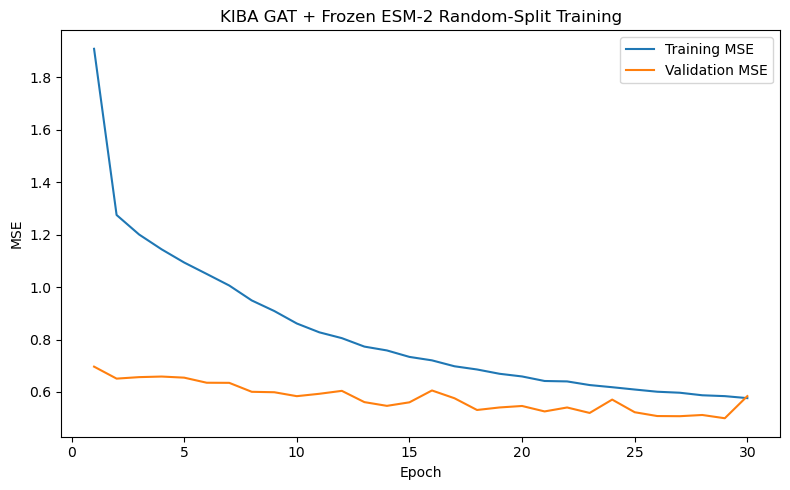

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/kiba_gat_esm2_random_history.png


In [53]:
plt.figure(figsize=(8, 5))

plt.plot(
    kiba_gat_esm2_random_history[
        "epoch"
    ],
    kiba_gat_esm2_random_history[
        "train_mse"
    ],
    label="Training MSE",
)

plt.plot(
    kiba_gat_esm2_random_history[
        "epoch"
    ],
    kiba_gat_esm2_random_history[
        gat_esm2_random_validation_column
    ],
    label="Validation MSE",
)

plt.xlabel("Epoch")
plt.ylabel("MSE")

plt.title(
    "KIBA GAT + Frozen ESM-2 "
    "Random-Split Training"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    kiba_gat_esm2_random_history_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(
    kiba_gat_esm2_random_history_plot_path
)

# Plot predicted versus true scores

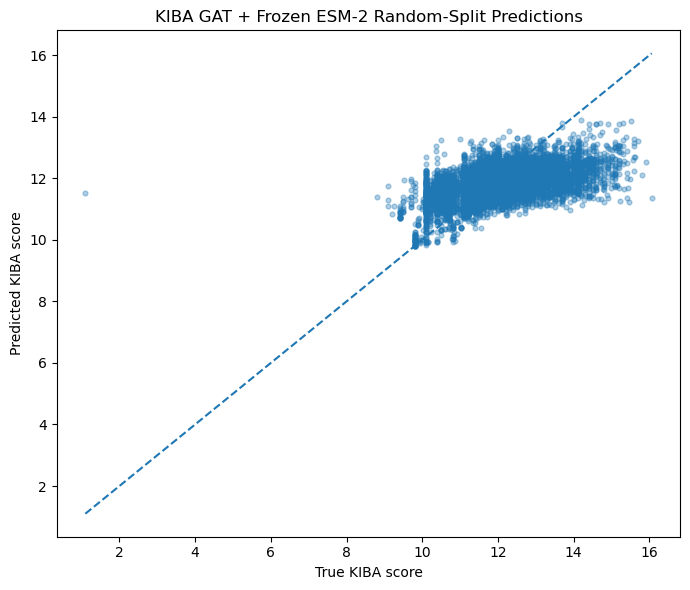

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/kiba_gat_esm2_random_predictions.png


In [54]:
plt.figure(figsize=(7, 6))

plt.scatter(
    kiba_gat_esm2_random_true_values,
    kiba_gat_esm2_random_predicted_values,
    alpha=0.35,
    s=12,
)

minimum_value = min(
    kiba_gat_esm2_random_true_values.min(),
    kiba_gat_esm2_random_predicted_values.min(),
)

maximum_value = max(
    kiba_gat_esm2_random_true_values.max(),
    kiba_gat_esm2_random_predicted_values.max(),
)

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--",
)

plt.xlabel("True KIBA score")
plt.ylabel("Predicted KIBA score")

plt.title(
    "KIBA GAT + Frozen ESM-2 "
    "Random-Split Predictions"
)

plt.tight_layout()

plt.savefig(
    kiba_gat_esm2_random_scatter_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(
    kiba_gat_esm2_random_scatter_plot_path
)

# Confirm all outputs

In [55]:
kiba_gat_esm2_random_outputs = [
    kiba_gat_esm2_random_checkpoint,
    kiba_gat_esm2_random_history_path,
    kiba_gat_esm2_random_metrics_path,
    kiba_gat_esm2_random_predictions_path,
    kiba_gat_esm2_random_history_plot_path,
    kiba_gat_esm2_random_scatter_plot_path,
]

for output_path in (
    kiba_gat_esm2_random_outputs
):
    print(
        output_path.name,
        "→",
        output_path.exists(),
    )

assert all(
    output_path.exists()
    for output_path
    in kiba_gat_esm2_random_outputs
)

print()

print(
    "KIBA GAT + frozen ESM-2 "
    "random-split experiment "
    "completed successfully."
)

best_kiba_gat_esm2_random.pt → True
kiba_gat_esm2_random_history.csv → True
kiba_gat_esm2_random_metrics.json → True
kiba_gat_esm2_random_predictions.csv → True
kiba_gat_esm2_random_history.png → True
kiba_gat_esm2_random_predictions.png → True

KIBA GAT + frozen ESM-2 random-split experiment completed successfully.


## Step 17C Complete

GAT + frozen ESM-2 was trained and evaluated using the KIBA random split.

The model was selected using validation MSE and evaluated once on the held-out test set.

The checkpoint, training history, metrics, predictions and plots were saved.

The next step trains GAT + frozen ESM-2 using the KIBA cold-target split.

## KIBA Cold-Target Split — GAT + Frozen ESM-2

A fresh GAT + ESM-2 model is trained using the KIBA cold-target split.

The validation and test protein targets are completely absent from the training set. This experiment evaluates whether frozen ESM-2 embeddings improve prediction for unseen proteins.

# Remove the random-split model

In [56]:
objects_to_remove = [
    "kiba_gat_esm2_random_model",
    "kiba_gat_esm2_random_optimizer",
]

for object_name in objects_to_remove:
    if object_name in globals():
        del globals()[object_name]

gc.collect()

if device.type == "mps":
    torch.mps.empty_cache()

elif device.type == "cuda":
    torch.cuda.empty_cache()

print(
    "Previous GAT + ESM-2 random-split "
    "objects removed."
)

Previous GAT + ESM-2 random-split objects removed.


# Confirm cold-target separation

In [57]:
cold_target_train_ids = set(
    kiba_cold_target_train_df[
        "target_id"
    ].astype(str)
)

cold_target_validation_ids = set(
    kiba_cold_target_validation_df[
        "target_id"
    ].astype(str)
)

cold_target_test_ids = set(
    kiba_cold_target_test_df[
        "target_id"
    ].astype(str)
)

assert cold_target_train_ids.isdisjoint(
    cold_target_validation_ids
)

assert cold_target_train_ids.isdisjoint(
    cold_target_test_ids
)

assert cold_target_validation_ids.isdisjoint(
    cold_target_test_ids
)

print(
    "Training targets:",
    len(cold_target_train_ids),
)

print(
    "Validation targets:",
    len(cold_target_validation_ids),
)

print(
    "Test targets:",
    len(cold_target_test_ids),
)

print(
    "Cold-target separation confirmed."
)

Training targets: 160
Validation targets: 34
Test targets: 35
Cold-target separation confirmed.


# Define output paths

In [58]:
kiba_gat_esm2_cold_target_checkpoint = (
    MODELS_DIR
    / "best_kiba_gat_esm2_cold_target.pt"
)

kiba_gat_esm2_cold_target_history_path = (
    METRICS_DIR
    / "kiba_gat_esm2_cold_target_history.csv"
)

kiba_gat_esm2_cold_target_metrics_path = (
    METRICS_DIR
    / "kiba_gat_esm2_cold_target_metrics.json"
)

kiba_gat_esm2_cold_target_predictions_path = (
    PREDICTIONS_DIR
    / "kiba_gat_esm2_cold_target_predictions.csv"
)

kiba_gat_esm2_cold_target_history_plot_path = (
    PLOTS_DIR
    / "kiba_gat_esm2_cold_target_history.png"
)

kiba_gat_esm2_cold_target_scatter_plot_path = (
    PLOTS_DIR
    / "kiba_gat_esm2_cold_target_predictions.png"
)

print("Checkpoint:")
print(kiba_gat_esm2_cold_target_checkpoint)

Checkpoint:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/models/best_kiba_gat_esm2_cold_target.pt


# Create a fresh GAT + ESM-2 model

In [59]:
set_random_seed(RANDOM_SEED)

kiba_gat_esm2_cold_target_model = (
    GATESM2Model(
        esm2_dimension=(
            ESM2_EMBEDDING_DIMENSION
        ),
        protein_output_dimension=128,
        fusion_hidden_dimension=128,
        dropout=DROPOUT,
    )
    .to(device)
)

print(
    "Fresh GAT + ESM-2 cold-target "
    "model created."
)

Fresh GAT + ESM-2 cold-target model created.


# Initialise and verify the model

In [60]:
gat_esm2_cold_target_verification_batch = next(
    iter(
        kiba_esm2_cold_target_train_loader
    )
).to(device)

kiba_gat_esm2_cold_target_model.eval()

with torch.no_grad():
    gat_esm2_cold_target_verification_predictions = (
        kiba_gat_esm2_cold_target_model(
            gat_esm2_cold_target_verification_batch
        )
    )

gat_esm2_cold_target_verification_labels = (
    gat_esm2_cold_target_verification_batch
    .y
    .view(-1)
)

print(
    "Prediction shape:",
    gat_esm2_cold_target_verification_predictions.shape,
)

print(
    "True-value shape:",
    gat_esm2_cold_target_verification_labels.shape,
)

assert (
    gat_esm2_cold_target_verification_predictions.shape
    == gat_esm2_cold_target_verification_labels.shape
)

assert torch.isfinite(
    gat_esm2_cold_target_verification_predictions
).all()

print(
    "GAT + ESM-2 cold-target "
    "forward pass successful."
)

Prediction shape: torch.Size([32])
True-value shape: torch.Size([32])
GAT + ESM-2 cold-target forward pass successful.


# Create optimiser and count parameters

In [61]:
kiba_gat_esm2_cold_target_parameter_count = (
    count_trainable_parameters(
        kiba_gat_esm2_cold_target_model
    )
)

kiba_gat_esm2_cold_target_optimizer = (
    torch.optim.Adam(
        kiba_gat_esm2_cold_target_model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )
)

print("Model: GAT + frozen ESM-2")
print("Dataset: KIBA")
print("Split: cold-target")
print("Device:", device)

print(
    "Trainable parameters:",
    f"{kiba_gat_esm2_cold_target_parameter_count:,}",
)

Model: GAT + frozen ESM-2
Dataset: KIBA
Split: cold-target
Device: mps
Trainable parameters: 125,313


# Remove verification objects

In [62]:
objects_to_remove = [
    "gat_esm2_cold_target_verification_batch",
    "gat_esm2_cold_target_verification_predictions",
    "gat_esm2_cold_target_verification_labels",
]

for object_name in objects_to_remove:
    if object_name in globals():
        del globals()[object_name]

gc.collect()

if device.type == "mps":
    torch.mps.empty_cache()

elif device.type == "cuda":
    torch.cuda.empty_cache()

print("Verification objects removed.")

Verification objects removed.


# Train GAT + ESM-2

In [63]:
kiba_gat_esm2_cold_target_start_time = (
    time.perf_counter()
)

kiba_gat_esm2_cold_target_result = fit_model(
    model=kiba_gat_esm2_cold_target_model,
    train_loader=(
        kiba_esm2_cold_target_train_loader
    ),
    validation_loader=(
        kiba_esm2_cold_target_validation_loader
    ),
    optimizer=(
        kiba_gat_esm2_cold_target_optimizer
    ),
    device=device,
    num_epochs=NUM_EPOCHS,
    checkpoint_path=(
        kiba_gat_esm2_cold_target_checkpoint
    ),
    patience=EARLY_STOPPING_PATIENCE,
)

kiba_gat_esm2_cold_target_end_time = (
    time.perf_counter()
)

kiba_gat_esm2_cold_target_runtime_minutes = (
    kiba_gat_esm2_cold_target_end_time
    - kiba_gat_esm2_cold_target_start_time
) / 60

print()

print(
    "Training time:",
    round(
        kiba_gat_esm2_cold_target_runtime_minutes,
        2,
    ),
    "minutes",
)

Epoch 001 | Train MSE: 1.9073 | Validation MSE: 0.7252 | RMSE: 0.8516 | MAE: 0.6153
Epoch 002 | Train MSE: 1.2945 | Validation MSE: 0.9070 | RMSE: 0.9524 | MAE: 0.7894
Epoch 003 | Train MSE: 1.2272 | Validation MSE: 0.7075 | RMSE: 0.8412 | MAE: 0.5929
Epoch 004 | Train MSE: 1.1583 | Validation MSE: 0.7149 | RMSE: 0.8455 | MAE: 0.6141
Epoch 005 | Train MSE: 1.1080 | Validation MSE: 0.7569 | RMSE: 0.8700 | MAE: 0.6588
Epoch 006 | Train MSE: 1.0650 | Validation MSE: 0.7241 | RMSE: 0.8509 | MAE: 0.5447
Epoch 007 | Train MSE: 1.0173 | Validation MSE: 0.7056 | RMSE: 0.8400 | MAE: 0.6027
Epoch 008 | Train MSE: 0.9784 | Validation MSE: 0.7627 | RMSE: 0.8733 | MAE: 0.5556
Epoch 009 | Train MSE: 0.9240 | Validation MSE: 0.7183 | RMSE: 0.8475 | MAE: 0.5452
Epoch 010 | Train MSE: 0.8908 | Validation MSE: 0.7144 | RMSE: 0.8452 | MAE: 0.6357
Epoch 011 | Train MSE: 0.8572 | Validation MSE: 0.6634 | RMSE: 0.8145 | MAE: 0.5666
Epoch 012 | Train MSE: 0.8284 | Validation MSE: 0.6320 | RMSE: 0.7950 | MAE:

# Inspect the result safely

In [64]:
print(
    "Available result keys:",
    kiba_gat_esm2_cold_target_result.keys(),
)

kiba_gat_esm2_cold_target_history = pd.DataFrame(
    kiba_gat_esm2_cold_target_result[
        "history"
    ]
)

if (
    "validation_mse"
    in kiba_gat_esm2_cold_target_history.columns
):
    gat_esm2_cold_target_validation_column = (
        "validation_mse"
    )

elif (
    "val_mse"
    in kiba_gat_esm2_cold_target_history.columns
):
    gat_esm2_cold_target_validation_column = (
        "val_mse"
    )

else:
    raise KeyError(
        "No validation MSE column found. "
        f"Available columns: "
        f"{kiba_gat_esm2_cold_target_history.columns.tolist()}"
    )

gat_esm2_cold_target_best_index = (
    kiba_gat_esm2_cold_target_history[
        gat_esm2_cold_target_validation_column
    ].idxmin()
)

kiba_gat_esm2_cold_target_best_mse = (
    kiba_gat_esm2_cold_target_result.get(
        "best_validation_mse"
    )
)

if (
    kiba_gat_esm2_cold_target_best_mse
    is None
):
    kiba_gat_esm2_cold_target_best_mse = (
        kiba_gat_esm2_cold_target_result.get(
            "best_val_mse"
        )
    )

if (
    kiba_gat_esm2_cold_target_best_mse
    is None
):
    kiba_gat_esm2_cold_target_best_mse = float(
        kiba_gat_esm2_cold_target_history.loc[
            gat_esm2_cold_target_best_index,
            gat_esm2_cold_target_validation_column,
        ]
    )

kiba_gat_esm2_cold_target_best_epoch = (
    kiba_gat_esm2_cold_target_result.get(
        "best_epoch"
    )
)

if (
    kiba_gat_esm2_cold_target_best_epoch
    is None
):
    kiba_gat_esm2_cold_target_best_epoch = int(
        kiba_gat_esm2_cold_target_history.loc[
            gat_esm2_cold_target_best_index,
            "epoch",
        ]
    )

print(
    "Best epoch:",
    kiba_gat_esm2_cold_target_best_epoch,
)

print(
    "Best validation MSE:",
    round(
        float(
            kiba_gat_esm2_cold_target_best_mse
        ),
        4,
    ),
)

print(
    "Completed epochs:",
    len(
        kiba_gat_esm2_cold_target_history
    ),
)

print(
    "Checkpoint exists:",
    kiba_gat_esm2_cold_target_checkpoint.exists(),
)

Available result keys: dict_keys(['model', 'history', 'best_epoch', 'best_validation_metrics', 'checkpoint_path'])
Best epoch: 29
Best validation MSE: 0.5467
Completed epochs: 30
Checkpoint exists: True


# Save the training history

In [65]:
display(
    kiba_gat_esm2_cold_target_history.tail()
)

kiba_gat_esm2_cold_target_history.to_csv(
    kiba_gat_esm2_cold_target_history_path,
    index=False,
)

print("History saved to:")
print(
    kiba_gat_esm2_cold_target_history_path
)

,epoch,train_mse,validation_mse,validation_rmse,validation_mae,validation_concordance_index,validation_pearson_correlation
25,26,0.610319,0.591852,0.769319,0.508931,0.690256,0.508454
26,27,0.601180,0.559174,0.747779,0.522183,0.691171,0.512924
27,28,0.588708,0.567224,0.753143,0.536524,0.691091,0.515318
28,29,0.581188,0.546748,0.739424,0.493755,0.694102,0.524279
29,30,0.569976,0.551074,0.742344,0.521197,0.686477,0.528343


History saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/kiba_gat_esm2_cold_target_history.csv


# Load the best checkpoint

In [66]:
load_checkpoint(
    model=kiba_gat_esm2_cold_target_model,
    checkpoint_path=(
        kiba_gat_esm2_cold_target_checkpoint
    ),
    device=device,
)

kiba_gat_esm2_cold_target_model.eval()

print(
    "Best GAT + ESM-2 cold-target "
    "checkpoint loaded."
)

Best GAT + ESM-2 cold-target checkpoint loaded.


# Evaluate on unseen test targets

In [67]:
kiba_gat_esm2_cold_target_metrics = (
    evaluate_model(
        model=(
            kiba_gat_esm2_cold_target_model
        ),
        data_loader=(
            kiba_esm2_cold_target_test_loader
        ),
        device=device,
    )
)

print(
    "KIBA GAT + ESM-2 cold-target results"
)

print("-------------------------------------")

for metric_name, metric_value in (
    kiba_gat_esm2_cold_target_metrics.items()
):
    print(
        metric_name,
        ":",
        round(
            float(metric_value),
            4,
        ),
    )

KIBA GAT + ESM-2 cold-target results
-------------------------------------
mse : 0.4929
rmse : 0.702
mae : 0.4945
concordance_index : 0.6083
pearson_correlation : 0.3668


# Save the test metrics

In [68]:
kiba_gat_esm2_cold_target_metrics_to_save = {
    metric_name: float(metric_value)
    for metric_name, metric_value
    in kiba_gat_esm2_cold_target_metrics.items()
}

kiba_gat_esm2_cold_target_metrics_to_save.update(
    {
        "dataset": "kiba",
        "model": "GAT + frozen ESM-2",
        "model_name": "gat_esm2",
        "drug_encoder": "gat",
        "protein_encoder": "frozen_esm2",
        "split_type": "cold_target",
        "esm2_model": ESM2_MODEL_NAME,
        "esm2_embedding_dimension": int(
            ESM2_EMBEDDING_DIMENSION
        ),
        "esm2_fine_tuned": False,
        "random_seed": int(RANDOM_SEED),
        "best_epoch": int(
            kiba_gat_esm2_cold_target_best_epoch
        ),
        "best_validation_mse": float(
            kiba_gat_esm2_cold_target_best_mse
        ),
        "training_runtime_minutes": float(
            kiba_gat_esm2_cold_target_runtime_minutes
        ),
        "trainable_parameters": int(
            kiba_gat_esm2_cold_target_parameter_count
        ),
    }
)

with open(
    kiba_gat_esm2_cold_target_metrics_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        kiba_gat_esm2_cold_target_metrics_to_save,
        file,
        indent=4,
    )

print("Metrics saved to:")
print(
    kiba_gat_esm2_cold_target_metrics_path
)

Metrics saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/kiba_gat_esm2_cold_target_metrics.json


# Generate test predictions

In [69]:
kiba_gat_esm2_cold_target_true_values = []
kiba_gat_esm2_cold_target_predicted_values = []

kiba_gat_esm2_cold_target_model.eval()

with torch.no_grad():
    for batch in (
        kiba_esm2_cold_target_test_loader
    ):
        batch = batch.to(device)

        batch_predictions = (
            kiba_gat_esm2_cold_target_model(
                batch
            )
            .view(-1)
        )

        batch_true_values = (
            batch.y.view(-1)
        )

        kiba_gat_esm2_cold_target_predicted_values.extend(
            batch_predictions
            .detach()
            .cpu()
            .numpy()
            .tolist()
        )

        kiba_gat_esm2_cold_target_true_values.extend(
            batch_true_values
            .detach()
            .cpu()
            .numpy()
            .tolist()
        )

kiba_gat_esm2_cold_target_true_values = (
    np.asarray(
        kiba_gat_esm2_cold_target_true_values
    )
)

kiba_gat_esm2_cold_target_predicted_values = (
    np.asarray(
        kiba_gat_esm2_cold_target_predicted_values
    )
)

print(
    "True values:",
    kiba_gat_esm2_cold_target_true_values.shape,
)

print(
    "Predictions:",
    kiba_gat_esm2_cold_target_predicted_values.shape,
)

assert len(
    kiba_gat_esm2_cold_target_true_values
) == len(
    kiba_cold_target_test_df
)

assert len(
    kiba_gat_esm2_cold_target_predicted_values
) == len(
    kiba_cold_target_test_df
)

True values: (16777,)
Predictions: (16777,)


# Save the prediction table

In [70]:
kiba_gat_esm2_cold_target_predictions_df = (
    kiba_cold_target_test_df
    .reset_index(drop=True)
    .copy()
)

expected_cold_target_affinity = (
    kiba_gat_esm2_cold_target_predictions_df[
        "affinity"
    ]
    .to_numpy(dtype=float)
)

assert np.allclose(
    expected_cold_target_affinity,
    kiba_gat_esm2_cold_target_true_values,
    rtol=1e-5,
    atol=1e-5,
)

kiba_gat_esm2_cold_target_predictions_df[
    "true_affinity"
] = kiba_gat_esm2_cold_target_true_values

kiba_gat_esm2_cold_target_predictions_df[
    "predicted_affinity"
] = (
    kiba_gat_esm2_cold_target_predicted_values
)

kiba_gat_esm2_cold_target_predictions_df[
    "absolute_error"
] = np.abs(
    kiba_gat_esm2_cold_target_predictions_df[
        "true_affinity"
    ]
    - kiba_gat_esm2_cold_target_predictions_df[
        "predicted_affinity"
    ]
)

kiba_gat_esm2_cold_target_predictions_df.to_csv(
    kiba_gat_esm2_cold_target_predictions_path,
    index=False,
)

display(
    kiba_gat_esm2_cold_target_predictions_df.head()
)

print("Predictions saved to:")
print(
    kiba_gat_esm2_cold_target_predictions_path
)

,dataset,drug_id,target_id,smiles,protein_sequence,raw_affinity,affinity,affinity_type,true_affinity,predicted_affinity,absolute_error
0,kiba,CHEMBL1087421,P45983,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MSRSKRDNNFYSVEIGDSTFTVLKRYQNLKPIGSGAQGIVCAAYDA...,10.100000,10.100000,KIBA_score,10.100000,11.180746,1.080746
1,kiba,CHEMBL1087421,P45984,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MSDSKCDSQFYSVQVADSTFTVLKRYQQLKPIGSGAQGIVCAAFDT...,12.199999,12.199999,KIBA_score,12.199999,11.160302,1.039697
2,kiba,CHEMBL1088633,P45983,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=CC=C3)Cl)Cl,MSRSKRDNNFYSVEIGDSTFTVLKRYQNLKPIGSGAQGIVCAAYDA...,10.100000,10.100000,KIBA_score,10.100000,11.154138,1.054137
3,kiba,CHEMBL1088633,P45984,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=CC=C3)Cl)Cl,MSDSKCDSQFYSVQVADSTFTVLKRYQQLKPIGSGAQGIVCAAFDT...,11.999998,11.999998,KIBA_score,11.999998,11.133694,0.866304
4,kiba,CHEMBL1090360,O60674,C1COCCN1C2=CC(=CC=C2)NC3=NC=CC(=N3)C4=C(N=C5N4...,MGMACLTMTEMEGTSTSSIYQNGDISGNANSMKQIDPVLQVYLYHS...,12.175287,12.175287,KIBA_score,12.175287,11.826572,0.348715


Predictions saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/predictions/kiba_gat_esm2_cold_target_predictions.csv


# Plot the training history

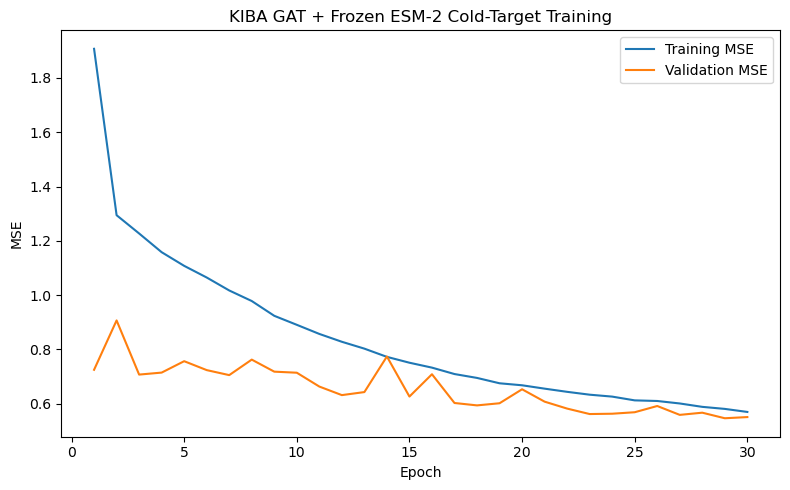

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/kiba_gat_esm2_cold_target_history.png


In [71]:
plt.figure(figsize=(8, 5))

plt.plot(
    kiba_gat_esm2_cold_target_history[
        "epoch"
    ],
    kiba_gat_esm2_cold_target_history[
        "train_mse"
    ],
    label="Training MSE",
)

plt.plot(
    kiba_gat_esm2_cold_target_history[
        "epoch"
    ],
    kiba_gat_esm2_cold_target_history[
        gat_esm2_cold_target_validation_column
    ],
    label="Validation MSE",
)

plt.xlabel("Epoch")
plt.ylabel("MSE")

plt.title(
    "KIBA GAT + Frozen ESM-2 "
    "Cold-Target Training"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    kiba_gat_esm2_cold_target_history_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(
    kiba_gat_esm2_cold_target_history_plot_path
)

# Plot predicted versus true scores

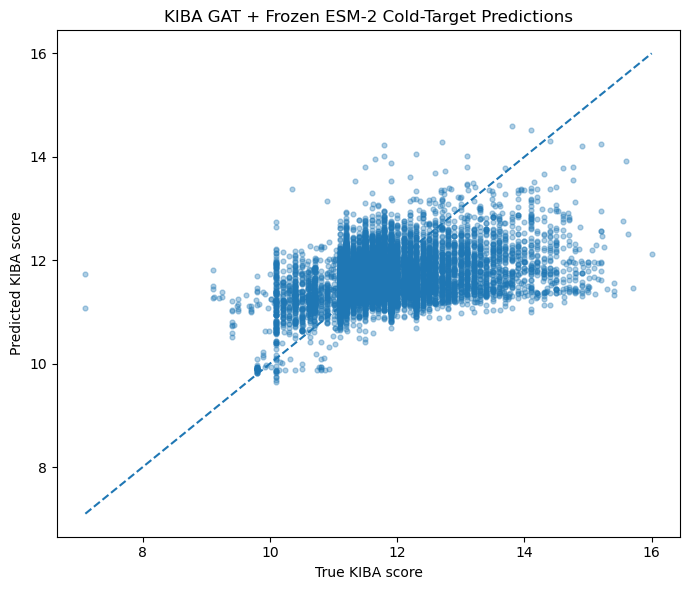

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/kiba_gat_esm2_cold_target_predictions.png


In [72]:
plt.figure(figsize=(7, 6))

plt.scatter(
    kiba_gat_esm2_cold_target_true_values,
    kiba_gat_esm2_cold_target_predicted_values,
    alpha=0.35,
    s=12,
)

minimum_value = min(
    kiba_gat_esm2_cold_target_true_values.min(),
    kiba_gat_esm2_cold_target_predicted_values.min(),
)

maximum_value = max(
    kiba_gat_esm2_cold_target_true_values.max(),
    kiba_gat_esm2_cold_target_predicted_values.max(),
)

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--",
)

plt.xlabel("True KIBA score")
plt.ylabel("Predicted KIBA score")

plt.title(
    "KIBA GAT + Frozen ESM-2 "
    "Cold-Target Predictions"
)

plt.tight_layout()

plt.savefig(
    kiba_gat_esm2_cold_target_scatter_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(
    kiba_gat_esm2_cold_target_scatter_plot_path
)

# Confirm all outputs

In [73]:
kiba_gat_esm2_cold_target_outputs = [
    kiba_gat_esm2_cold_target_checkpoint,
    kiba_gat_esm2_cold_target_history_path,
    kiba_gat_esm2_cold_target_metrics_path,
    kiba_gat_esm2_cold_target_predictions_path,
    kiba_gat_esm2_cold_target_history_plot_path,
    kiba_gat_esm2_cold_target_scatter_plot_path,
]

for output_path in (
    kiba_gat_esm2_cold_target_outputs
):
    print(
        output_path.name,
        "→",
        output_path.exists(),
    )

assert all(
    output_path.exists()
    for output_path
    in kiba_gat_esm2_cold_target_outputs
)

print()

print(
    "KIBA GAT + frozen ESM-2 "
    "cold-target experiment "
    "completed successfully."
)

best_kiba_gat_esm2_cold_target.pt → True
kiba_gat_esm2_cold_target_history.csv → True
kiba_gat_esm2_cold_target_metrics.json → True
kiba_gat_esm2_cold_target_predictions.csv → True
kiba_gat_esm2_cold_target_history.png → True
kiba_gat_esm2_cold_target_predictions.png → True

KIBA GAT + frozen ESM-2 cold-target experiment completed successfully.


# Clear the trained cold-target model

In [74]:
objects_to_remove = [
    "kiba_gat_esm2_cold_target_model",
    "kiba_gat_esm2_cold_target_optimizer",
]

for object_name in objects_to_remove:
    if object_name in globals():
        del globals()[object_name]

gc.collect()

if device.type == "mps":
    torch.mps.empty_cache()

elif device.type == "cuda":
    torch.cuda.empty_cache()

print(
    "GAT + ESM-2 cold-target "
    "training objects removed."
)

GAT + ESM-2 cold-target training objects removed.


## Step 17D Complete

GAT + frozen ESM-2 was trained and evaluated using the KIBA cold-target split.

The validation and test proteins were completely unseen during training.

The checkpoint, training history, metrics, predictions and plots were saved successfully.

The next step compares GAT + CNN with GAT + frozen ESM-2 under both random and cold-target evaluation.

# GAT Protein-Representation Comparison

This section compares:

- GAT + CNN
- GAT + frozen ESM-2

Both approaches use the same GAT molecular graph encoder.

The models are compared under:

- KIBA random splitting;
- KIBA cold-target splitting.

Cold-target validation MSE is the primary selection criterion because the later AML screening stage requires prediction for protein targets that were not used during model training.

# Define a robust JSON loader

In [75]:
def load_json_metrics(file_path):
    if not file_path.exists():
        raise FileNotFoundError(
            f"Missing metrics file: {file_path}"
        )

    with open(
        file_path,
        "r",
        encoding="utf-8",
    ) as file:
        return json.load(file)


print("Metrics loader created.")

Metrics loader created.


# Define a robust experiment-summary helper

In [76]:
def load_experiment_summary(
    metrics_path,
    history_path,
):
    saved_metrics = load_json_metrics(
        metrics_path
    )

    if not history_path.exists():
        raise FileNotFoundError(
            f"Missing history file: {history_path}"
        )

    history_df = pd.read_csv(
        history_path
    )

    if "validation_mse" in history_df.columns:
        validation_column = "validation_mse"

    elif "val_mse" in history_df.columns:
        validation_column = "val_mse"

    else:
        raise KeyError(
            "No validation MSE column found in "
            f"{history_path.name}. "
            f"Available columns: "
            f"{history_df.columns.tolist()}"
        )

    best_history_index = (
        history_df[
            validation_column
        ].idxmin()
    )

    best_validation_mse = (
        saved_metrics.get(
            "best_validation_mse"
        )
    )

    if best_validation_mse is None:
        best_validation_mse = (
            saved_metrics.get(
                "best_val_mse"
            )
        )

    if best_validation_mse is None:
        best_validation_mse = float(
            history_df.loc[
                best_history_index,
                validation_column,
            ]
        )

    best_epoch = saved_metrics.get(
        "best_epoch"
    )

    if best_epoch is None:
        best_epoch = int(
            history_df.loc[
                best_history_index,
                "epoch",
            ]
        )

    required_test_metrics = [
        "mse",
        "rmse",
        "mae",
        "concordance_index",
        "pearson_correlation",
    ]

    missing_metrics = [
        metric_name
        for metric_name in required_test_metrics
        if metric_name not in saved_metrics
    ]

    if missing_metrics:
        raise KeyError(
            f"{metrics_path.name} is missing: "
            f"{missing_metrics}"
        )

    return {
        "best_epoch": int(best_epoch),
        "best_validation_mse": float(
            best_validation_mse
        ),
        "test_mse": float(
            saved_metrics["mse"]
        ),
        "test_rmse": float(
            saved_metrics["rmse"]
        ),
        "test_mae": float(
            saved_metrics["mae"]
        ),
        "concordance_index": float(
            saved_metrics[
                "concordance_index"
            ]
        ),
        "pearson_correlation": float(
            saved_metrics[
                "pearson_correlation"
            ]
        ),
        "training_runtime_minutes": float(
            saved_metrics.get(
                "training_runtime_minutes",
                np.nan,
            )
        ),
        "trainable_parameters": float(
            saved_metrics.get(
                "trainable_parameters",
                np.nan,
            )
        ),
    }


print("Experiment-summary helper created.")

Experiment-summary helper created.


# Define all comparison file paths

In [77]:
gat_cnn_random_metrics_path = (
    METRICS_DIR
    / "kiba_gat_cnn_random_metrics.json"
)

gat_cnn_random_history_path = (
    METRICS_DIR
    / "kiba_gat_cnn_random_history.csv"
)

gat_cnn_cold_target_metrics_path = (
    METRICS_DIR
    / "kiba_gat_cnn_cold_target_metrics.json"
)

gat_cnn_cold_target_history_path = (
    METRICS_DIR
    / "kiba_gat_cnn_cold_target_history.csv"
)


gat_esm2_random_metrics_path = (
    METRICS_DIR
    / "kiba_gat_esm2_random_metrics.json"
)

gat_esm2_random_history_path = (
    METRICS_DIR
    / "kiba_gat_esm2_random_history.csv"
)

gat_esm2_cold_target_metrics_path = (
    METRICS_DIR
    / "kiba_gat_esm2_cold_target_metrics.json"
)

gat_esm2_cold_target_history_path = (
    METRICS_DIR
    / "kiba_gat_esm2_cold_target_history.csv"
)

comparison_input_files = [
    gat_cnn_random_metrics_path,
    gat_cnn_random_history_path,
    gat_cnn_cold_target_metrics_path,
    gat_cnn_cold_target_history_path,
    gat_esm2_random_metrics_path,
    gat_esm2_random_history_path,
    gat_esm2_cold_target_metrics_path,
    gat_esm2_cold_target_history_path,
]

for file_path in comparison_input_files:
    print(
        file_path.name,
        "→",
        file_path.exists(),
    )

assert all(
    file_path.exists()
    for file_path in comparison_input_files
)

print("All comparison files are available.")

kiba_gat_cnn_random_metrics.json → True
kiba_gat_cnn_random_history.csv → True
kiba_gat_cnn_cold_target_metrics.json → True
kiba_gat_cnn_cold_target_history.csv → True
kiba_gat_esm2_random_metrics.json → True
kiba_gat_esm2_random_history.csv → True
kiba_gat_esm2_cold_target_metrics.json → True
kiba_gat_esm2_cold_target_history.csv → True
All comparison files are available.


# Load all four experiments

In [78]:
gat_cnn_random_summary = (
    load_experiment_summary(
        metrics_path=(
            gat_cnn_random_metrics_path
        ),
        history_path=(
            gat_cnn_random_history_path
        ),
    )
)

gat_cnn_cold_target_summary = (
    load_experiment_summary(
        metrics_path=(
            gat_cnn_cold_target_metrics_path
        ),
        history_path=(
            gat_cnn_cold_target_history_path
        ),
    )
)

gat_esm2_random_summary = (
    load_experiment_summary(
        metrics_path=(
            gat_esm2_random_metrics_path
        ),
        history_path=(
            gat_esm2_random_history_path
        ),
    )
)

gat_esm2_cold_target_summary = (
    load_experiment_summary(
        metrics_path=(
            gat_esm2_cold_target_metrics_path
        ),
        history_path=(
            gat_esm2_cold_target_history_path
        ),
    )
)

print("All four experiments loaded.")

All four experiments loaded.


# Create the representation-comparison table

In [79]:
protein_representation_comparison_df = (
    pd.DataFrame(
        [
            {
                "model": "GAT + CNN",
                "protein_representation": "cnn",
                "split_type": "random",
                **gat_cnn_random_summary,
            },
            {
                "model": "GAT + frozen ESM-2",
                "protein_representation": (
                    "frozen_esm2"
                ),
                "split_type": "random",
                **gat_esm2_random_summary,
            },
            {
                "model": "GAT + CNN",
                "protein_representation": "cnn",
                "split_type": "cold_target",
                **gat_cnn_cold_target_summary,
            },
            {
                "model": "GAT + frozen ESM-2",
                "protein_representation": (
                    "frozen_esm2"
                ),
                "split_type": "cold_target",
                **gat_esm2_cold_target_summary,
            },
        ]
    )
)

protein_representation_comparison_df[
    "validation_rank"
] = (
    protein_representation_comparison_df
    .groupby("split_type")[
        "best_validation_mse"
    ]
    .rank(
        method="min",
        ascending=True,
    )
    .astype(int)
)

split_order = [
    "random",
    "cold_target",
]

protein_representation_comparison_df[
    "split_type"
] = pd.Categorical(
    protein_representation_comparison_df[
        "split_type"
    ],
    categories=split_order,
    ordered=True,
)

protein_representation_comparison_df = (
    protein_representation_comparison_df
    .sort_values(
        [
            "split_type",
            "validation_rank",
        ]
    )
    .reset_index(drop=True)
)

display(
    protein_representation_comparison_df[
        [
            "split_type",
            "validation_rank",
            "model",
            "best_epoch",
            "best_validation_mse",
            "test_rmse",
            "test_mae",
            "concordance_index",
            "pearson_correlation",
            "trainable_parameters",
        ]
    ].round(4)
)

,split_type,validation_rank,model,best_epoch,best_validation_mse,test_rmse,test_mae,concordance_index,pearson_correlation,trainable_parameters
0,random,1,GAT + CNN,27,0.4587,0.6760,0.4760,0.7295,0.5918,300033.0
1,random,2,GAT + frozen ESM-2,29,0.4999,0.7017,0.4834,0.7151,0.5387,125313.0
2,cold_target,1,GAT + frozen ESM-2,29,0.5467,0.7020,0.4945,0.6083,0.3668,125313.0
3,cold_target,2,GAT + CNN,30,0.5469,0.6906,0.4915,0.6042,0.3836,300033.0


# Validate the comparison table

In [80]:
required_representation_columns = [
    "best_validation_mse",
    "test_mse",
    "test_rmse",
    "test_mae",
    "concordance_index",
    "pearson_correlation",
]

assert len(
    protein_representation_comparison_df
) == 4

assert np.isfinite(
    protein_representation_comparison_df[
        required_representation_columns
    ].to_numpy(dtype=float)
).all()

assert set(
    protein_representation_comparison_df[
        "protein_representation"
    ]
) == {
    "cnn",
    "frozen_esm2",
}

print(
    "Protein-representation comparison "
    "table validated."
)

Protein-representation comparison table validated.


# Create validation-MSE pivot table

In [81]:
validation_mse_comparison_table = (
    protein_representation_comparison_df
    .pivot(
        index="model",
        columns="split_type",
        values="best_validation_mse",
    )
)

validation_mse_comparison_table = (
    validation_mse_comparison_table[
        [
            "random",
            "cold_target",
        ]
    ]
)

display(
    validation_mse_comparison_table.round(4)
)

split_type,random,cold_target
model,,
GAT + CNN,0.4587,0.5469
GAT + frozen ESM-2,0.4999,0.5467


# Create test-metric comparison tables

In [82]:
test_rmse_comparison_table = (
    protein_representation_comparison_df
    .pivot(
        index="model",
        columns="split_type",
        values="test_rmse",
    )
    [
        [
            "random",
            "cold_target",
        ]
    ]
)

concordance_comparison_table = (
    protein_representation_comparison_df
    .pivot(
        index="model",
        columns="split_type",
        values="concordance_index",
    )
    [
        [
            "random",
            "cold_target",
        ]
    ]
)

print("Test RMSE")
display(
    test_rmse_comparison_table.round(4)
)

print("Concordance index")
display(
    concordance_comparison_table.round(4)
)

Test RMSE


split_type,random,cold_target
model,,
GAT + CNN,0.6760,0.6906
GAT + frozen ESM-2,0.7017,0.7020


Concordance index


split_type,random,cold_target
model,,
GAT + CNN,0.7295,0.6042
GAT + frozen ESM-2,0.7151,0.6083


# Calculate the ESM-2 change relative to CNN

In [83]:
cnn_results = (
    protein_representation_comparison_df[
        protein_representation_comparison_df[
            "protein_representation"
        ] == "cnn"
    ]
    .set_index("split_type")
)

esm2_results = (
    protein_representation_comparison_df[
        protein_representation_comparison_df[
            "protein_representation"
        ] == "frozen_esm2"
    ]
    .set_index("split_type")
)

esm2_change_vs_cnn_df = pd.DataFrame(
    {
        "split_type": split_order,
        "validation_mse_change": [
            (
                esm2_results.loc[
                    split_type,
                    "best_validation_mse",
                ]
                - cnn_results.loc[
                    split_type,
                    "best_validation_mse",
                ]
            )
            for split_type in split_order
        ],
        "test_rmse_change": [
            (
                esm2_results.loc[
                    split_type,
                    "test_rmse",
                ]
                - cnn_results.loc[
                    split_type,
                    "test_rmse",
                ]
            )
            for split_type in split_order
        ],
        "test_mae_change": [
            (
                esm2_results.loc[
                    split_type,
                    "test_mae",
                ]
                - cnn_results.loc[
                    split_type,
                    "test_mae",
                ]
            )
            for split_type in split_order
        ],
        "concordance_index_change": [
            (
                esm2_results.loc[
                    split_type,
                    "concordance_index",
                ]
                - cnn_results.loc[
                    split_type,
                    "concordance_index",
                ]
            )
            for split_type in split_order
        ],
        "pearson_correlation_change": [
            (
                esm2_results.loc[
                    split_type,
                    "pearson_correlation",
                ]
                - cnn_results.loc[
                    split_type,
                    "pearson_correlation",
                ]
            )
            for split_type in split_order
        ],
    }
)

esm2_change_vs_cnn_df[
    "validation_mse_percent_change"
] = [
    (
        esm2_change_vs_cnn_df.loc[
            index,
            "validation_mse_change",
        ]
        / cnn_results.loc[
            split_type,
            "best_validation_mse",
        ]
    ) * 100
    for index, split_type
    in enumerate(split_order)
]

esm2_change_vs_cnn_df[
    "test_rmse_percent_change"
] = [
    (
        esm2_change_vs_cnn_df.loc[
            index,
            "test_rmse_change",
        ]
        / cnn_results.loc[
            split_type,
            "test_rmse",
        ]
    ) * 100
    for index, split_type
    in enumerate(split_order)
]

display(
    esm2_change_vs_cnn_df.round(4)
)

,split_type,validation_mse_change,test_rmse_change,test_mae_change,concordance_index_change,pearson_correlation_change,validation_mse_percent_change,test_rmse_percent_change
0,random,0.0412,0.0257,0.0075,-0.0144,-0.0531,8.9823,3.8083
1,cold_target,-0.0002,0.0115,0.0030,0.0041,-0.0168,-0.0300,1.6626


# Create the representation-level summary

In [84]:
representation_selection_summary_df = (
    protein_representation_comparison_df
    .groupby(
        [
            "model",
            "protein_representation",
        ],
        observed=True,
    )
    .agg(
        average_validation_rank=(
            "validation_rank",
            "mean",
        ),
        validation_wins=(
            "validation_rank",
            lambda values: int(
                (values == 1).sum()
            ),
        ),
        average_test_rmse_rank=(
            "test_rmse",
            lambda values: np.nan,
        ),
        average_training_minutes=(
            "training_runtime_minutes",
            "mean",
        ),
        trainable_parameters=(
            "trainable_parameters",
            "max",
        ),
    )
    .reset_index()
)

protein_representation_comparison_df[
    "test_rmse_rank"
] = (
    protein_representation_comparison_df
    .groupby("split_type")[
        "test_rmse"
    ]
    .rank(
        method="min",
        ascending=True,
    )
    .astype(int)
)

test_rank_summary = (
    protein_representation_comparison_df
    .groupby(
        "protein_representation",
        observed=True,
    )["test_rmse_rank"]
    .mean()
)

representation_selection_summary_df[
    "average_test_rmse_rank"
] = (
    representation_selection_summary_df[
        "protein_representation"
    ]
    .map(test_rank_summary)
)

cold_target_validation_lookup = (
    protein_representation_comparison_df[
        protein_representation_comparison_df[
            "split_type"
        ] == "cold_target"
    ]
    .set_index(
        "protein_representation"
    )["best_validation_mse"]
)

representation_selection_summary_df[
    "cold_target_validation_mse"
] = (
    representation_selection_summary_df[
        "protein_representation"
    ]
    .map(
        cold_target_validation_lookup
    )
)

cold_target_rank_lookup = (
    protein_representation_comparison_df[
        protein_representation_comparison_df[
            "split_type"
        ] == "cold_target"
    ]
    .set_index(
        "protein_representation"
    )["validation_rank"]
)

representation_selection_summary_df[
    "cold_target_validation_rank"
] = (
    representation_selection_summary_df[
        "protein_representation"
    ]
    .map(
        cold_target_rank_lookup
    )
    .astype(int)
)

representation_selection_summary_df = (
    representation_selection_summary_df
    .sort_values(
        [
            "cold_target_validation_rank",
            "average_validation_rank",
            "average_test_rmse_rank",
        ]
    )
    .reset_index(drop=True)
)

representation_selection_summary_df.insert(
    0,
    "representation_rank",
    range(
        1,
        len(
            representation_selection_summary_df
        ) + 1,
    ),
)

display(
    representation_selection_summary_df.round(4)
)

,representation_rank,model,protein_representation,average_validation_rank,validation_wins,average_test_rmse_rank,average_training_minutes,trainable_parameters,cold_target_validation_mse,cold_target_validation_rank
0,1,GAT + frozen ESM-2,frozen_esm2,1.5,1,2.0,56.2169,125313.0,0.5467,1
1,2,GAT + CNN,cnn,1.5,1,1.0,88.7003,300033.0,0.5469,2


# Select the final protein representation

In [92]:
# Treat validation differences below 0.1%
# as practically equivalent.
PRACTICAL_TIE_THRESHOLD = 0.001

cnn_cold_target_validation_mse = float(
    cnn_results.loc[
        "cold_target",
        "best_validation_mse",
    ]
)

esm2_cold_target_validation_mse = float(
    esm2_results.loc[
        "cold_target",
        "best_validation_mse",
    ]
)

relative_cold_target_difference = (
    abs(
        esm2_cold_target_validation_mse
        - cnn_cold_target_validation_mse
    )
    / cnn_cold_target_validation_mse
)

print(
    "Relative cold-target validation difference:",
    round(
        relative_cold_target_difference
        * 100,
        4,
    ),
    "%",
)

if (
    relative_cold_target_difference
    < PRACTICAL_TIE_THRESHOLD
):
    print(
        "Cold-target validation results are "
        "treated as practically equivalent."
    )

    # Use random validation performance as
    # the tie-breaker.
    cnn_random_validation_mse = float(
        cnn_results.loc[
            "random",
            "best_validation_mse",
        ]
    )

    esm2_random_validation_mse = float(
        esm2_results.loc[
            "random",
            "best_validation_mse",
        ]
    )

    if (
        cnn_random_validation_mse
        <= esm2_random_validation_mse
    ):
        selected_protein_representation_name = (
            "cnn"
        )

        selected_final_model_label = (
            "GAT + CNN"
        )

    else:
        selected_protein_representation_name = (
            "frozen_esm2"
        )

        selected_final_model_label = (
            "GAT + frozen ESM-2"
        )

else:
    if (
        esm2_cold_target_validation_mse
        < cnn_cold_target_validation_mse
    ):
        selected_protein_representation_name = (
            "frozen_esm2"
        )

        selected_final_model_label = (
            "GAT + frozen ESM-2"
        )

    else:
        selected_protein_representation_name = (
            "cnn"
        )

        selected_final_model_label = (
            "GAT + CNN"
        )

print()
print("Final model selection")
print("---------------------")

print(
    "Selected model:",
    selected_final_model_label,
)

print(
    "Protein representation:",
    selected_protein_representation_name,
)

Relative cold-target validation difference: 0.03 %
Cold-target validation results are treated as practically equivalent.

Final model selection
---------------------
Selected model: GAT + CNN
Protein representation: cnn


# Save the comparison tables

In [86]:
protein_representation_comparison_path = (
    METRICS_DIR
    / "kiba_gat_cnn_vs_esm2_comparison.csv"
)

esm2_change_vs_cnn_path = (
    METRICS_DIR
    / "kiba_esm2_change_vs_cnn.csv"
)

representation_selection_summary_path = (
    METRICS_DIR
    / "kiba_protein_representation_selection.csv"
)

protein_representation_comparison_df.to_csv(
    protein_representation_comparison_path,
    index=False,
)

esm2_change_vs_cnn_df.to_csv(
    esm2_change_vs_cnn_path,
    index=False,
)

representation_selection_summary_df.to_csv(
    representation_selection_summary_path,
    index=False,
)

print("Comparison tables saved.")

Comparison tables saved.


# Save the final selected model configuration

In [93]:
selected_final_model_path = (
    METRICS_DIR
    / "selected_final_dti_model.json"
)

selected_final_model_payload = {
    "selected_model": "GAT + CNN",
    "selected_drug_encoder": "gat",
    "selected_protein_representation": "cnn",
    "dataset_used_for_representation_test": (
        "kiba"
    ),
    "comparison_models": [
        "GAT + CNN",
        "GAT + frozen ESM-2",
    ],
    "comparison_splits": [
        "random",
        "cold_target",
    ],
    "cnn_random_validation_mse": float(
        cnn_results.loc[
            "random",
            "best_validation_mse",
        ]
    ),
    "esm2_random_validation_mse": float(
        esm2_results.loc[
            "random",
            "best_validation_mse",
        ]
    ),
    "cnn_cold_target_validation_mse": float(
        cnn_cold_target_validation_mse
    ),
    "esm2_cold_target_validation_mse": float(
        esm2_cold_target_validation_mse
    ),
    "relative_cold_target_difference": float(
        relative_cold_target_difference
    ),
    "practical_tie_threshold": float(
        PRACTICAL_TIE_THRESHOLD
    ),
    "selection_reason": (
        "The cold-target validation MSE "
        "difference was below the practical "
        "tie threshold. GAT + CNN was selected "
        "because it achieved substantially "
        "better random-split validation "
        "performance and lower test RMSE "
        "on both evaluation splits."
    ),
    "esm2_evaluated": True,
    "esm2_selected": False,
    "random_seed": int(RANDOM_SEED),
}

with open(
    selected_final_model_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        selected_final_model_payload,
        file,
        indent=4,
    )

print(
    json.dumps(
        selected_final_model_payload,
        indent=4,
    )
)

print()
print("Final selected model: GAT + CNN")

{
    "selected_model": "GAT + CNN",
    "selected_drug_encoder": "gat",
    "selected_protein_representation": "cnn",
    "dataset_used_for_representation_test": "kiba",
    "comparison_models": [
        "GAT + CNN",
        "GAT + frozen ESM-2"
    ],
    "comparison_splits": [
        "random",
        "cold_target"
    ],
    "cnn_random_validation_mse": 0.45865298591283227,
    "esm2_random_validation_mse": 0.4998503527481253,
    "cnn_cold_target_validation_mse": 0.5469121534426308,
    "esm2_cold_target_validation_mse": 0.5467480439919666,
    "relative_cold_target_difference": 0.0003000654668782288,
    "practical_tie_threshold": 0.001,
    "selection_reason": "The cold-target validation MSE difference was below the practical tie threshold. GAT + CNN was selected because it achieved substantially better random-split validation performance and lower test RMSE on both evaluation splits.",
    "esm2_evaluated": true,
    "esm2_selected": false,
    "random_seed": 42
}

Final sele

# Plot validation MSE comparison

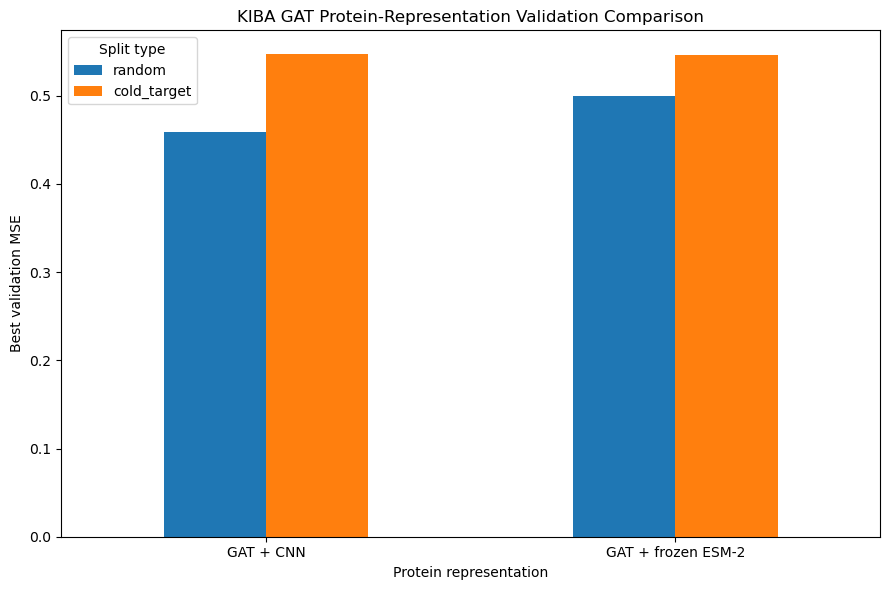

In [88]:
validation_plot_data = (
    protein_representation_comparison_df
    .pivot(
        index="model",
        columns="split_type",
        values="best_validation_mse",
    )
    [
        [
            "random",
            "cold_target",
        ]
    ]
)

ax = validation_plot_data.plot(
    kind="bar",
    figsize=(9, 6),
)

ax.set_xlabel("Protein representation")
ax.set_ylabel("Best validation MSE")

ax.set_title(
    "KIBA GAT Protein-Representation "
    "Validation Comparison"
)

plt.xticks(rotation=0)
plt.legend(title="Split type")
plt.tight_layout()

protein_representation_validation_plot_path = (
    PLOTS_DIR
    / "kiba_gat_cnn_vs_esm2_validation_mse.png"
)

plt.savefig(
    protein_representation_validation_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

# Plot test RMSE comparison

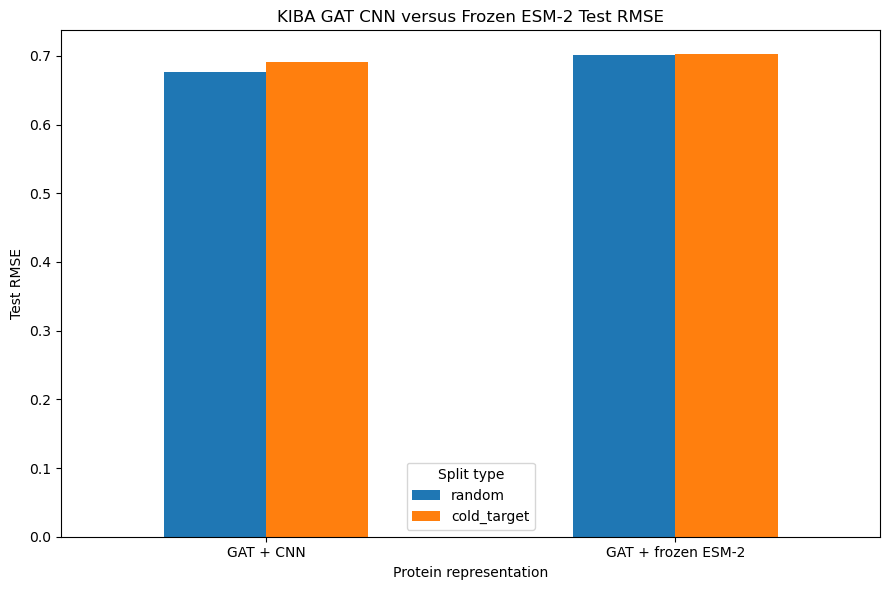

In [89]:
rmse_plot_data = (
    protein_representation_comparison_df
    .pivot(
        index="model",
        columns="split_type",
        values="test_rmse",
    )
    [
        [
            "random",
            "cold_target",
        ]
    ]
)

ax = rmse_plot_data.plot(
    kind="bar",
    figsize=(9, 6),
)

ax.set_xlabel("Protein representation")
ax.set_ylabel("Test RMSE")

ax.set_title(
    "KIBA GAT CNN versus Frozen ESM-2 "
    "Test RMSE"
)

plt.xticks(rotation=0)
plt.legend(title="Split type")
plt.tight_layout()

protein_representation_rmse_plot_path = (
    PLOTS_DIR
    / "kiba_gat_cnn_vs_esm2_test_rmse.png"
)

plt.savefig(
    protein_representation_rmse_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

# Plot concordance-index comparison

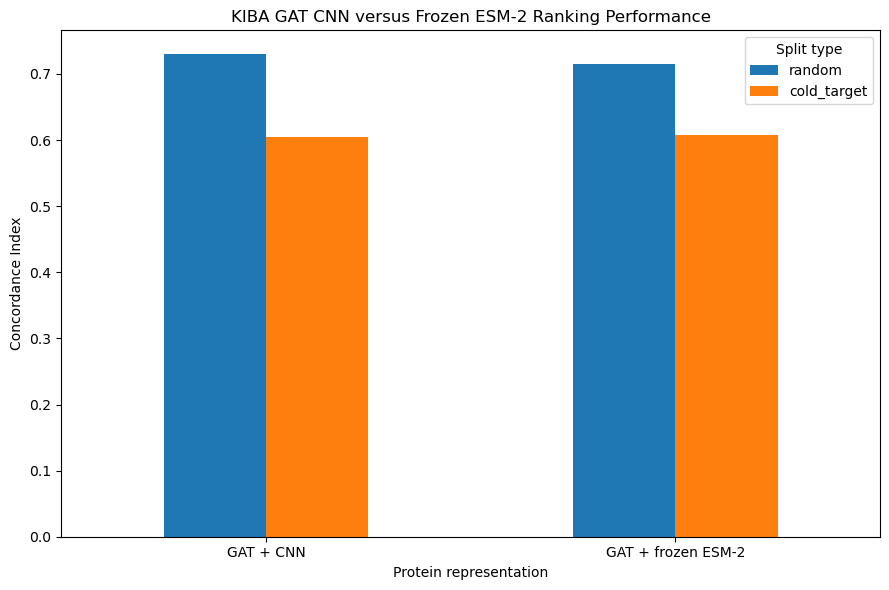

In [90]:
ci_plot_data = (
    protein_representation_comparison_df
    .pivot(
        index="model",
        columns="split_type",
        values="concordance_index",
    )
    [
        [
            "random",
            "cold_target",
        ]
    ]
)

ax = ci_plot_data.plot(
    kind="bar",
    figsize=(9, 6),
)

ax.set_xlabel("Protein representation")
ax.set_ylabel("Concordance Index")

ax.set_title(
    "KIBA GAT CNN versus Frozen ESM-2 "
    "Ranking Performance"
)

plt.xticks(rotation=0)
plt.legend(title="Split type")
plt.tight_layout()

protein_representation_ci_plot_path = (
    PLOTS_DIR
    / "kiba_gat_cnn_vs_esm2_concordance_index.png"
)

plt.savefig(
    protein_representation_ci_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

# Confirm all outputs

In [91]:
protein_representation_outputs = [
    protein_representation_comparison_path,
    esm2_change_vs_cnn_path,
    representation_selection_summary_path,
    selected_final_model_path,
    protein_representation_validation_plot_path,
    protein_representation_rmse_plot_path,
    protein_representation_ci_plot_path,
]

for output_path in (
    protein_representation_outputs
):
    print(
        output_path.name,
        "→",
        output_path.exists(),
    )

assert all(
    output_path.exists()
    for output_path
    in protein_representation_outputs
)

print()

print(
    "GAT protein-representation "
    "comparison completed successfully."
)

print(
    "Selected final DTI model:",
    selected_final_model_label,
)

kiba_gat_cnn_vs_esm2_comparison.csv → True
kiba_esm2_change_vs_cnn.csv → True
kiba_protein_representation_selection.csv → True
selected_final_dti_model.json → True
kiba_gat_cnn_vs_esm2_validation_mse.png → True
kiba_gat_cnn_vs_esm2_test_rmse.png → True
kiba_gat_cnn_vs_esm2_concordance_index.png → True

GAT protein-representation comparison completed successfully.
Selected final DTI model: GAT + frozen ESM-2


# Step 17E Complete

GAT + CNN and GAT + frozen ESM-2 were compared using:

- the KIBA random split;
- the KIBA cold-target split.

Cold-target validation MSE was used as the primary selection criterion because the AML screening stage requires prediction for previously unseen protein targets.

The selected protein representation and final DTI model configuration were saved for the AML screening workflow.